# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [157]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [158]:
clients = pd.read_csv(f"S16/{RAW_CLIENTS}",
    parse_dates = ['app_last_login', 'card_open_date', 'registration_date','birth_date']
)
transactions = pd.read_csv(f"S16/{RAW_TXN}",
    sep=';',
    encoding='cp1251',
    decimal=',',
    parse_dates=['txn_datetime'])
transactions["txn_datetime"] = pd.to_datetime(
    transactions["txn_datetime"],
    format="mixed",
)    

C:\Users\mihai\AppData\Local\Temp\ipykernel_17936\1905713901.py:1: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  clients = pd.read_csv(f"S16/{RAW_CLIENTS}",
C:\Users\mihai\AppData\Local\Temp\ipykernel_17936\1905713901.py:1: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  clients = pd.read_csv(f"S16/{RAW_CLIENTS}",


In [159]:
clients

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001205,1980-11-08,М,СПб,Зарплатный,Серебро,Дебетовая,2021-02-18,2023-06-16,Зарплата в нашем банке,120700.0,Да,2024-07-01,NaN,350,Да
1,C001505,1972-04-10,М,Новосибирск,Премиальный,Золото,Премиальная,2018-04-07,2019-10-28,Зарплата в другом банке,200700.0,Да,2025-05-01,5.0,727,Да
2,C004047,1983-08-09,М,Нижний Новгород,Премиальный,Платина,Дебетовая,2014-04-15,2019-06-10,Зарплата в нашем банке,139800.0,Да,2024-02-01,NaN,473,Да
3,C001681,1967-05-06,Ж,МОСКВА,Премиальный,Золото,Дебетовая,2017-01-16,2021-07-15,Зарплата в другом банке,179200.0,Нет,NaT,5.0,673,Нет
4,C001032,1988-06-29,М,Москва,Зарплатный,Серебро,Дебетовая,2019-12-13,2022-09-10,Зарплата в нашем банке,76600.0,Нет,NaT,NaN,750,Да
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5676,C001603,1981-01-13,М,Санкт-Петербург,Премиальный,Серебро,Кредитная,2017-07-11,2021-08-16,Не указан,132000.0,Да,2024-05-01,NaN,302,Да
5677,C000813,1954-10-09,Ж,Н. Новгород,Массовый,Базовый,Дебетовая,2018-11-13,2020-07-03,Зарплата в другом банке,85800.0,Да,2025-06-01,3.0,339,Да
5678,C000263,1979-09-22,Ж,Москва,Массовый,Базовый,Дебетовая,2019-02-09,2023-02-06,Зарплата в другом банке,44200.0,Нет,NaT,NaN,206,Да
5679,C003315,1982-11-19,М,ЕКАТЕРИНБУРГ,Массовый,Базовый,Дебетовая,2021-12-14,2024-08-24,Зарплата в нашем банке,50100.0,Да,2024-03-01,NaN,685,Да


In [160]:
transactions

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990082,C002337,2023-11-23 12:35:01,22.85,RUB,Транспорт,4111,Карта,успешно
1,990202,C004788,2023-12-19 15:03:49,6233.55,RUB,Одежда и обувь,5651,Карта,успешно
2,990105,C005290,2023-12-27 16:49:20,351.80,RUB,Онлайн-сервисы,5815,Карта,успешно
3,990167,C000119,2023-12-27 21:19:57,814.67,RUB,Продукты,5411,Карта,успешно
4,100001,C001100,2024-01-01 00:33:34,1941.64,RUB,Развлечения и досуг,7832,Карта,успешно
...,...,...,...,...,...,...,...,...,...
625953,990210,C004641,2026-06-22 17:33:15,500.66,RUB,Связь и Интернет,4814,СБП,успешно
625954,990045,C001125,2026-07-02 12:30:44,235.51,RUB,Связь и интернет,4814,Токен,успешно
625955,990186,C003605,2026-07-13 09:11:12,1748.30,RUB,АЗС,5541,Карта,успешно
625956,990012,C001513,2026-07-15 09:42:32,7173.87,RUB,Развлечения и досуг,7832,Карта,успешно


In [161]:
transactions.describe()

,txn_id,txn_datetime,amount,mcc_code
count,625958.000000,625958,625958.000000,625958.000000
mean,413360.461435,2024-09-24 22:28:55.999556,1869.042662,5589.990365
min,100001.000000,2023-11-23 12:35:01,-69411.070000,4111.000000
25%,256138.250000,2024-05-19 10:16:37.500000,469.602500,5411.000000
50%,412248.500000,2024-09-21 14:41:54.500000,1071.740000,5541.000000
75%,568357.750000,2025-01-26 12:18:51.500000,2265.400000,5812.000000
max,990220.000000,2026-07-18 16:16:04,116208.020000,7832.000000
std,181911.745983,NaN,2693.101821,857.761675


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [162]:
print(clients.info())

<class 'pandas.DataFrame'>
RangeIndex: 5681 entries, 0 to 5680
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5681 non-null   str           
 1   birth_date          5681 non-null   datetime64[us]
 2   gender              5681 non-null   str           
 3   city                5681 non-null   str           
 4   segment             5681 non-null   str           
 5   loyalty_tier        5681 non-null   str           
 6   card_type           5681 non-null   str           
 7   registration_date   5681 non-null   datetime64[us]
 8   card_open_date      5681 non-null   datetime64[us]
 9   income_source       5681 non-null   str           
 10  monthly_income      5119 non-null   float64       
 11  has_mobile_app      5681 non-null   str           
 12  app_last_login      3508 non-null   datetime64[us]
 13  satisfaction_score  2319 non-null   float64       
 14  bra

In [163]:
n_clients = len(clients)
client_missing = clients.isna().sum()
client_missing = client_missing[client_missing > 0].rename("n_missing").to_frame()
client_missing["n_rows"] = n_clients
client_missing["share"] = client_missing["n_missing"] / n_clients
print(client_missing)

n_txn = len(transactions)
print("Строк transactions:", n_txn)
print("Пропусков в transactions:", int(transactions.isna().sum().sum()))

                    n_missing  n_rows     share
monthly_income            562    5681  0.098926
app_last_login           2173    5681  0.382503
satisfaction_score       3362    5681  0.591797
Строк transactions: 625958
Пропусков в transactions: 0


In [164]:
pd.crosstab(
    clients["has_mobile_app"],
    clients["app_last_login"].isna(),
    rownames=["has_mobile_app"],
    colnames=["app_last_login пустой"],
)

app_last_login пустой,False,True
has_mobile_app,,
Да,3508,0
Нет,0,2173


In [165]:
n_clients = len(clients)
score_missing = clients["satisfaction_score"].isna()
print("Пустая оценка:", int(score_missing.sum()), "из", n_clients)
pd.crosstab(
    clients["has_mobile_app"],
    score_missing,
    rownames=["has_mobile_app"],
    colnames=["satisfaction_score пустой"],
)

Пустая оценка: 3362 из 5681


satisfaction_score пустой,False,True
has_mobile_app,,
Да,1447,2061
Нет,872,1301


Пропуски — число пустых значений и доля от всех строк таблицы. Для clients знаменатель доли равен числу строк справочника, для transactions — числу операций.

app_last_login пустой у клиентов без приложения.

satisfaction_score пустой у большинства строк, доля почти одинакова с приложением и без него.

In [166]:
print(clients['monthly_income'].describe())

count      5119.000000
mean      95433.055069
std       81698.396661
min        -999.000000
25%       51450.000000
50%       73400.000000
75%      110000.000000
max      907600.000000
Name: monthly_income, dtype: float64


In [167]:
print("Клиентов с месячным доходом < 1000:",len(clients[clients['monthly_income']<=1000]))
print("Клиентов с месячным доходом < 10000:",len(clients[clients['monthly_income']<=10000]))

Клиентов с месячным доходом < 1000: 208
Клиентов с месячным доходом < 10000: 208


Минимальный месячный доход -999. Также у 208 человек доход меньше 1000 рублей, при этом больше ни у кого нет дохода < 10000, эти 208 записей - ошибочные.

In [168]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 625958 entries, 0 to 625957
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        625958 non-null  int64         
 1   client_id     625958 non-null  str           
 2   txn_datetime  625958 non-null  datetime64[us]
 3   amount        625958 non-null  float64       
 4   currency      625958 non-null  str           
 5   category      625958 non-null  str           
 6   mcc_code      625958 non-null  int64         
 7   channel       625958 non-null  str           
 8   status        625958 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 76.6 MB


В transactions пропусков нет.

Ключи: client_id для clients, 1 строка - 1 клиент и txn_id для transactions, 1 строка - 1 транзакция.

### 2.2. Дубли

In [169]:
print('Одинаковых строк в clients:',clients.duplicated().sum())
print('Клиентов с одинаковым client_id:',clients['client_id'].duplicated().sum())
print('Одинаковых строк в transactions:',transactions.duplicated().sum())
print('Клиентов с одинаковым txn_id:',transactions['txn_id'].duplicated().sum())

Одинаковых строк в clients: 40
Клиентов с одинаковым client_id: 55


Одинаковых строк в transactions: 1288
Клиентов с одинаковым txn_id: 1500


In [170]:
txn_dups = transactions[transactions["txn_id"].duplicated(keep=False)]
nunq = txn_dups.groupby("txn_id").nunique(dropna=False)

other = [c for c in nunq.columns if c != "txn_datetime"]
only_dt = nunq.index[nunq["txn_datetime"].gt(1) & nunq[other].eq(1).all(axis=1)]
print(len(only_dt))

transactions[transactions["txn_id"].isin(only_dt)].sort_values(["txn_id", "txn_datetime"])

212


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
1371,101363,C003125,2024-01-02 00:00:00,1492.74,RUB,АЗС,5541,Онлайн-банк,успешно
1370,101363,C003125,2024-01-02 20:40:52,1492.74,RUB,АЗС,5541,Онлайн-банк,успешно
2097,102088,C001721,2024-01-03 00:00:00,446.03,RUB,Продукты,5411,Карта,успешно
2098,102088,C001721,2024-01-03 19:08:17,446.03,RUB,Продукты,5411,Карта,успешно
2653,102642,C002861,2024-01-04 00:00:00,197.91,RUB,Онлайн-сервисы,5815,СБП,успешно
...,...,...,...,...,...,...,...,...,...
615282,718905,C005410,2025-06-21 06:09:04,1452.18,RUB,Развлечения и досуг,7832,Токен,отклонено
618536,722151,C002351,2025-06-23 00:00:00,7399.68,RUB,Одежда и обувь,5651,Онлайн-банк,успешно
618537,722151,C002351,2025-06-23 08:49:19,7399.68,RUB,Одежда и обувь,5651,Онлайн-банк,успешно
623850,727445,C000412,2025-06-28 00:00:00,9099.03,RUB,Одежда и обувь,5651,Токен,успешно


У всех записей transactions с одинаковым txn_id, но различием в другом поле отличаются txn_datetime - в одной записи время произвольное в другой 00:00:00, соответственно такие дупликаты можно просто удалить.

In [171]:
client_dups = clients[clients["client_id"].duplicated(keep=False)].sort_values("client_id")
client_dups.loc[~client_dups.duplicated(keep=False)]

nunq = client_dups.groupby("client_id").nunique(dropna=False)
other = [c for c in nunq.columns if c != "client_id"]
diff_ids = nunq.index[nunq[other].gt(1).any(axis=1)]
print(nunq.loc[diff_ids, other].gt(1).sum())
clients[clients["client_id"].isin(diff_ids)].sort_values("client_id")

birth_date             0
gender                 0
city                  15
segment               14
loyalty_tier           0
card_type              0
registration_date      0
card_open_date         0
income_source          0
monthly_income         0
has_mobile_app         0
app_last_login         0
satisfaction_score     0
branch_code            0
marketing_opt_in       0
dtype: int64


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
1922,C000018,1976-12-09,М,Екатеринбург,Массовый,Серебро,Кредитная,2014-01-20,2019-05-18,Зарплата в нашем банке,88000.0,Нет,NaT,NaN,294,Да
2720,C000018,1976-12-09,М,Казань,Премиальный,Серебро,Кредитная,2014-01-20,2019-05-18,Зарплата в нашем банке,88000.0,Нет,NaT,NaN,294,Да
702,C000133,1983-12-26,М,Санкт Петербург,Массовый,Базовый,Дебетовая,2019-07-25,2019-10-10,Зарплата в другом банке,40500.0,Да,2024-06-01,4.0,701,Да
4380,C000133,1983-12-26,М,Москва,Премиальный,Базовый,Дебетовая,2019-07-25,2019-10-10,Зарплата в другом банке,40500.0,Да,2024-06-01,4.0,701,Да
2553,C000255,1977-01-30,М,москва,Премиальный,Серебро,Дебетовая,2016-07-06,2022-04-11,Зарплата в другом банке,176500.0,Да,2025-05-01,NaN,131,Нет
5442,C000255,1977-01-30,М,Новосибирск,Private,Серебро,Дебетовая,2016-07-06,2022-04-11,Зарплата в другом банке,176500.0,Да,2025-05-01,NaN,131,Нет
3623,C000463,1960-01-24,Ж,Новосибирск,Зарплатный,Базовый,Кредитная,2019-06-19,2021-07-26,Не указан,72300.0,Да,2024-01-01,3.0,802,Да
5509,C000463,1960-01-24,Ж,москва,Массовый,Базовый,Кредитная,2019-06-19,2021-07-26,Не указан,72300.0,Да,2024-01-01,3.0,802,Да
933,C001092,1974-03-05,М,казань,Массовый,Базовый,Дебетовая,2014-01-28,2017-06-07,Не указан,38200.0,Да,2025-05-01,NaN,407,Да
1013,C001092,1974-03-05,М,Казань,Массовый,Базовый,Дебетовая,2014-01-28,2017-06-07,Не указан,38200.0,Да,2025-05-01,NaN,407,Да


Некоторые дублирующие записи clients происходят из-за разного написания городов, другие из-за различных сегментов. Названия городов можно исправить на одинаковые. Если у одного client_id разные города или сегменты то меняем их на "Неопределено".

### 2.3. Соответствие данных описанию полей из задания

In [172]:
print(clients.dtypes)
print(transactions.dtypes)

client_id                        str
birth_date            datetime64[us]
gender                           str
city                             str
segment                          str
loyalty_tier                     str
card_type                        str
registration_date     datetime64[us]
card_open_date        datetime64[us]
income_source                    str
monthly_income               float64
has_mobile_app                   str
app_last_login        datetime64[us]
satisfaction_score           float64
branch_code                    int64
marketing_opt_in                 str
dtype: object
txn_id                   int64
client_id                  str
txn_datetime    datetime64[us]
amount                 float64
currency                   str
category                   str
mcc_code                 int64
channel                    str
status                     str
dtype: object


Типы совпадают с описанием полей. Даты в clients и txn_datetime считаются как дата и время, monthly_income и amount — как числа, коды и категории — как строки. 

In [173]:
print("Указано в задании:", 9)
print("В файле:", transactions["category"].nunique())

Указано в задании: 9
В файле: 12


In [174]:
expected = {
    "АЗС",
    "Аптеки",
    "Кафе и рестораны",
    "Одежда и обувь",
    "Онлайн-сервисы",
    "Продукты",
    "Развлечения и досуг",
    "Связь и интернет",
    "Транспорт",
}
transactions.loc[~transactions["category"].isin(expected), "category"].value_counts()

category
Связь и Интернет    19717
кафе и рестораны    16298
Кафе/рестораны      16056
Name: count, dtype: int64

В задании 9 категорий, в файле 12 так как есть 3 варианта «кафе и рестораны» и 2 варианта «связь и интернет». По смыслу это те же девять категорий.

In [175]:
clients["city"].value_counts().sort_index()

city
 москва                162
ЕКАТЕРИНБУРГ           139
Екатеринбург           640
Казань                 589
МОСКВА                 166
Москва                1091
Н. Новгород            174
Нижний Новгород        558
Новосибирск            542
СПб                     91
Санкт Петербург         88
Санкт-Петербург        646
г. Москва              184
г. Новосибирск         167
г. Санкт-Петербург     110
г.Екатеринбург         152
казань                 182
Name: count, dtype: int64

В файле 17 написаний шести городов: Москва, Санкт-Петербург, Казань, Екатеринбург, Новосибирск и Нижний Новгород.

In [176]:
start = pd.Timestamp("2024-01-01")
end = pd.Timestamp("2025-07-01")
outside = (transactions["txn_datetime"] < start) | (transactions["txn_datetime"] >= end)
print("В файле txn_datetime от", transactions["txn_datetime"].min(), "до", transactions["txn_datetime"].max())
print("В задании окно 2024-01-01 .. 2025-06-30")
print("Вне окна:", int(outside.sum()), "из", len(transactions))
print("Раньше 2024-01-01:", int((transactions["txn_datetime"] < start).sum()))
print("Позже 2025-06-30:", int((transactions["txn_datetime"] >= end).sum()))


В файле txn_datetime от 2023-11-23 12:35:01 до 2026-07-18 16:16:04
В задании окно 2024-01-01 .. 2025-06-30
Вне окна: 99 из 625958
Раньше 2024-01-01: 4
Позже 2025-06-30: 95


В задании операции охватывают 2024-01-01 .. 2025-06-30. В файле даты с 2023-11-23 по 2026-07-18: вне окна 99 из 625958, 4 раньше и 95 позже. Формат даты верный. Перед расчётом активности эти строки убираем: после удаления дублей их по-прежнему 99, а после отсечения операций без клиента остаётся 95.

### 2.4. Связь между таблицами

In [177]:
print(
    "Операций без клиента(в clients нет соответствующего client_id для транзакции):",
    int((~transactions["client_id"].isin(clients["client_id"])).sum()),
    "из", len(transactions),
)
print(
    "Клиентов без операций(в transactions нет записей с client_id как в clients):",
    int((~clients["client_id"].isin(transactions["client_id"])).sum()),
    "из", len(clients),
)
dup_ids = clients.loc[clients["client_id"].duplicated(keep=False), "client_id"]
print(
    "Операций, у которых client_id встречается в clients дважды:",
    int(transactions["client_id"].isin(dup_ids).sum()),
    "из", len(transactions),
    "|таких client_id:", int(dup_ids.nunique()),
)

Операций без клиента(в clients нет соответствующего client_id для транзакции): 31165 из 625958
Клиентов без операций(в transactions нет записей с client_id как в clients): 6 из 5681
Операций, у которых client_id встречается в clients дважды: 6012 из 625958 |таких client_id: 55


Операции без клиента, 31165 из 625958, нельзя связать со строкой справочника. Для расчёта по клиентам они не используются, их можно убрать из рабочей таблицы операций.

Клиентов без операций 6 из 5681. В справочнике их оставляем. По карте у них нет ни одной операции, поэтому падение активности им не из чего считать и в группу по падению они не попадают.

55 client_id записаны в clients двумя строками, на них приходится 6012 операций. Пока в справочнике две строки на один id, соединение таблиц удвоит эти операции. После того как для каждого такого id останется одна строка, удвоения не будет.

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

**Выводы по аудиту.** В справочнике 5681 строка, операций 625958.

Доход не выше 1000 рублей у 208 из 5119 заполненных, следующий доход уже 16000. Эти 208 записей ошибочные, в разрез по доходу их не берём. Пустой доход — другое: 562 из 5681, и по полям не видно, что он низкий. app_last_login пустой у 2173 из 5681, ровно у клиентов без приложения.

Лишние полные копии: 40 строк в clients и 1288 в transactions, вторая удаляется. Ещё 212 пар операций отличаются только временем: у одной строки полночь, удаляется она. У 15 client_id расходятся город или сегмент, эти поля ставим «Неопределено».

Город записан 17 написаниями на 6 городов, категория — 12 написаниями на 9 категорий. Перед разрезами написания нужно свести.

31165 операций из 625958 не находят клиента в справочнике, в расчёт по клиентам они не входят. 6 клиентов без операций остаются в справочнике, падение им не посчитать. Пока у 55 client_id по две строки, соединение удвоит 6012 операций.


Операции в файле с 2023-11-23 по 2026-07-18. Вне окна задания 2024-01-01 .. 2025-06-30 лежит 99 из 625958. В расчёт активности они не входят.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [178]:
transactions = transactions.sort_values(["txn_id", "txn_datetime"])
transactions = transactions.drop_duplicates(subset = ['txn_id'],keep='last')
clients = clients.drop_duplicates()

Удаляем полные дубликаты из clients и дубликаты по txn_id из transactions: отличия только во времени, сохраняем ту версию, где время определено.


99 операций вне окна 2024-01-01 .. 2025-06-30 здесь не удаляем: дата прочитана верно, отбор по периоду стоит перед расчётом активности.

### 3.2. Категориальные признаки

In [179]:
cities = {
    " москва": "Москва",
    "москва": "Москва",
    "МОСКВА": "Москва",
    "г. Москва": "Москва",
    "ЕКАТЕРИНБУРГ": "Екатеринбург",
    "г.Екатеринбург": "Екатеринбург",
    "казань": "Казань",
    "Н. Новгород": "Нижний Новгород",
    "г. Новосибирск": "Новосибирск",
    "СПб": "Санкт-Петербург",
    "Санкт Петербург": "Санкт-Петербург",
    "г. Санкт-Петербург": "Санкт-Петербург",
}
clients["city"] = clients["city"].replace(cities)

cats = {
    "Связь и Интернет": "Связь и интернет",
    "кафе и рестораны": "Кафе и рестораны",
    "Кафе/рестораны": "Кафе и рестораны",
}
transactions["category"] = transactions["category"].replace(cats)

dup = clients["client_id"].duplicated(keep=False)
nunq = clients.loc[dup].groupby("client_id")[["city", "segment"]].nunique()
for col in ["city", "segment"]:
    ids = nunq.index[nunq[col] > 1]
    clients.loc[clients["client_id"].isin(ids), col] = "Неопределено"
clients = clients.drop_duplicates()


Сводим 17 написаний городов к шести. Три лишних написания категорий приводим к 'Связь и интернет' и 'Кафе и рестораны', остальные не меняются. Если у одного client_id после этого всё ещё различаются город или сегмент, эти поля ставим Неопределено и оставляем одну строку.

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [180]:
valid_income = clients.loc[clients["monthly_income"] > 1000, "monthly_income"]
income_median = valid_income.median()
clients["income_imputed"] = clients["monthly_income"].isna()
clients["monthly_income"] = clients["monthly_income"].fillna(income_median)
print("Медиана реальных доходов:", income_median)
print("Заполнено пропусков:", int(clients["income_imputed"].sum()))


Медиана реальных доходов: 75000.0
Заполнено пропусков: 555


Пустой доход — 555 из 5626 строк после удаления дублей. Почему значение не указано, по остальным полям не видно. Пропуски заполняем медианой доходов выше 1000 рублей, это 75000.Новый столбец income_imputed для строк, где доход был пустым. 208 ошибочных значений в медиану не входят.

app_last_login пустой у клиентов без приложения, 2151 из 5626. Входа не было, поэтому дату не заполняем. satisfaction_score пустой у 3329 из 5626 оставляем пустым так как опрос не пройден. В transactions пропусков нет.

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [181]:
print("Даты:")
print(clients[["birth_date", "registration_date", "card_open_date", "app_last_login"]].agg(["min", "max"]))
print("Сумма операции:")
print(transactions["amount"].agg(["min", "median", "max"]))
print("Доход выше 1000 рублей:")
print(clients.loc[clients["monthly_income"] > 1000, "monthly_income"].agg(["min", "median", "max"]))
start = pd.Timestamp("2024-01-01")
end = pd.Timestamp("2025-07-01")
outside = (transactions["txn_datetime"] < start) | (transactions["txn_datetime"] >= end)
print("Окно задания: 2024-01-01 .. 2025-06-30")
print(transactions["txn_datetime"].agg(["min", "max"]))
print("Операций вне окна:", int(outside.sum()), "из", len(transactions))


Даты:
    birth_date registration_date card_open_date app_last_login
min 1936-07-25        2010-01-18     2016-01-01     2024-01-01
max 2002-10-20        2025-04-12     2025-05-16     2025-06-01
Сумма операции:
min       -69411.070
median      1071.605
max       116208.020
Name: amount, dtype: float64
Доход выше 1000 рублей:
min        16000.0
median     75000.0
max       907600.0
Name: monthly_income, dtype: float64
Окно задания: 2024-01-01 .. 2025-06-30
min   2023-11-23 12:35:01
max   2026-07-18 16:16:04
Name: txn_datetime, dtype: datetime64[us]
Операций вне окна: 99 из 624458


Даты клиентов в обычных границах. У операций минимум 2023-11-23 и максимум 2026-07-18: 99 из 624458 вне окна 2024-01-01 .. 2025-06-30. Это не выброс, такие строки убирает фильтр периода.

In [182]:
low_income = clients.loc[clients["monthly_income"] <= 1000, "monthly_income"]
print("Доход не выше 1000 рублей:", len(low_income))
print(low_income.agg(["min", "max"]))
print("Следующий доход:", clients.loc[clients["monthly_income"] > 1000, "monthly_income"].min())


Доход не выше 1000 рублей: 206
min   -999.0
max    569.0
Name: monthly_income, dtype: float64
Следующий доход: 16000.0


In [183]:
purchases = transactions.loc[transactions["amount"] > 0, "amount"]
print("Отрицательных сумм:",
    int((transactions["amount"] < 0).sum()),
    "| из них со статусом «возврат»:",
    int(((transactions["amount"] < 0) & (transactions["status"] == "возврат")).sum()),
)

Отрицательных сумм: 7448 | из них со статусом «возврат»: 7448


Отрицательные суммы это не выброс, они имеют статус возврат.

In [184]:
clients["false_income"] = clients.index.isin(low_income.index)
clients.loc[clients["false_income"], "monthly_income"] = income_median
print(clients["false_income"].value_counts())

false_income
False    5420
True      206
Name: count, dtype: int64


У 206 клиентов доход не выше 1000 рублей: false_income для них True, для остальных False. В monthly_income им ставим медиану 75000. Больше выбросов нет.

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [185]:
n_in = len(transactions)
has_client = transactions["client_id"].isin(clients["client_id"])
print("На входе:", n_in)
print("Нет client_id в справочнике:", int((~has_client).sum()))
transactions = transactions.loc[has_client].copy()
print("Осталось:", len(transactions))

start = pd.Timestamp("2024-01-01")
end = pd.Timestamp("2025-07-01")
in_window = (transactions["txn_datetime"] >= start) & (transactions["txn_datetime"] < end)
print("Дата вне 2024-01-01 .. 2025-06-30:", int((~in_window).sum()))
transactions = transactions.loc[in_window].copy()
print("Осталось:", len(transactions))

base = (transactions["txn_datetime"] >= start) & (transactions["txn_datetime"] < "2025-01-01")
evaluated = (transactions["txn_datetime"] >= "2025-01-01") & (transactions["txn_datetime"] < end)
print("Базовый период, 2024:", int(base.sum()))
print("Оцениваемый период, январь–июнь 2025:", int(evaluated.sum()))
no_txn = ~clients["client_id"].isin(transactions["client_id"])
print("Клиентов без операций, в справочнике оставляем:", int(no_txn.sum()), "из", len(clients))


На входе: 624458
Нет client_id в справочнике: 31093
Осталось: 593365
Дата вне 2024-01-01 .. 2025-06-30: 95
Осталось: 593270
Базовый период, 2024: 418889
Оцениваемый период, январь–июнь 2025: 174381
Клиентов без операций, в справочнике оставляем: 6 из 5626


На входе 624458 операций после удаления дублей. 31093 нельзя связать с клиентом: падение по ним не посчитать, эти строки удаляем из transactions. Ещё 95 операций раньше 2024-01-01 или позже 2025-06-30, они не входят ни в один из двух периодов, их тоже удаляем из transactions.

Остаётся 593270 операций: 418889 за 2024 год и 174381 за январь–июнь 2025. Шесть клиентов без операций из справочника не удаляем: это действующие клиенты, по карте у них пусто, и падение им не из чего считать.

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [186]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [187]:
rows = [
    {
        "field": "client_id",
        "issue": "полная копия строки справочника",
        "scope": "clients, вторая идентичная строка",
        "n_rows": 40,
        "value_before": "две одинаковые строки одного клиента",
        "action": "удалено",
        "value_after": "одна строка",
        "rationale": "копия не добавляет клиента и удвоила бы его при соединении таблиц",
    },
    {
        "field": "txn_id",
        "issue": "повтор идентификатора операции",
        "scope": "transactions",
        "n_rows": 1500,
        "value_before": "1288 полных копий и 212 копий с временем 00:00:00",
        "action": "удалено",
        "value_after": "одна строка на txn_id; если было два времени, остаётся более позднее",
        "rationale": "один txn_id — одна операция, полночь была той же операцией без времени",
    },
    {
        "field": "city",
        "issue": "17 написаний шести городов",
        "scope": "строки с неканоническим написанием после удаления полных копий",
        "n_rows": 1603,
        "value_before": "например «г. Москва», «МОСКВА», « москва»",
        "action": "исправлено",
        "value_after": "Москва, Санкт-Петербург, Казань, Екатеринбург, Новосибирск, Нижний Новгород",
        "rationale": "смысл города тот же, разное написание разбило бы один город на несколько",
    },
    {
        "field": "category",
        "issue": "три лишних написания двух категорий",
        "scope": "строки с этими написаниями после удаления дублей txn_id",
        "n_rows": 51939,
        "value_before": "«кафе и рестораны», «Кафе/рестораны», «Связь и Интернет»",
        "action": "исправлено",
        "value_after": "«Кафе и рестораны», «Связь и интернет»",
        "rationale": "в задании девять категорий, варианты отличаются только регистром и знаками",
    },
    {
        "field": "city",
        "issue": "у одного client_id после сведения написаний остались разные города",
        "scope": "12 client_id, обе строки каждого",
        "n_rows": 24,
        "value_before": "два разных города",
        "action": "исправлено",
        "value_after": "Неопределено",
        "rationale": "выбрать один город нельзя: это не варианты написания",
    },
    {
        "field": "segment",
        "issue": "у одного client_id разные сегменты",
        "scope": "14 client_id, обе строки каждого",
        "n_rows": 28,
        "value_before": "два разных сегмента",
        "action": "исправлено",
        "value_after": "Неопределено",
        "rationale": "по остальным полям строки совпадают, основание выбрать сегмент отсутствует",
    },
    {
        "field": "client_id",
        "issue": "после правки города и сегмента строки одного id совпали",
        "scope": "15 лишних строк clients",
        "n_rows": 15,
        "value_before": "вторая строка того же client_id",
        "action": "удалено",
        "value_after": "одна строка на client_id, всего 5626",
        "rationale": "строки больше не различаются, вторая снова была копией",
    },
    {
        "field": "monthly_income",
        "issue": "пропуск дохода",
        "scope": "пустые значения после удаления дублей clients",
        "n_rows": 555,
        "value_before": "пусто",
        "action": "заполнено",
        "value_after": "75000, income_imputed=True",
        "rationale": "медиана доходов выше 1000 рублей; почему доход не указан, по другим полям не видно",
    },
    {
        "field": "monthly_income",
        "issue": "доход не выше 1000 отделён пустым промежутком от 16000",
        "scope": "206 строк, значения от -999 до 569",
        "n_rows": 206,
        "value_before": "от -999 до 569",
        "action": "заполнено",
        "value_after": "75000, false_income=True",
        "rationale": "между 569 и 16000 доходов нет, -999 не похож на доход; в разрез по доходу эти строки не брать",
    },
    {
        "field": "client_id",
        "issue": "операция без клиента в справочнике",
        "scope": "transactions после удаления дублей txn_id",
        "n_rows": 31093,
        "value_before": "client_id нет в clients",
        "action": "удалено",
        "value_after": "строка удалена из transactions",
        "rationale": "падение активности не к кому отнести и в группу кампании некого поставить",
    },
    {
        "field": "txn_datetime",
        "issue": "дата вне окна 2024-01-01 .. 2025-06-30",
        "scope": "операции с клиентом вне этого окна",
        "n_rows": 95,
        "value_before": "даты с 2023-11-23 по 2026-07-18",
        "action": "удалено",
        "value_after": "остаются операции с 2024-01-01 по 2025-06-30, всего 593270",
        "rationale": "эти операции не входят ни в базовый 2024 год, ни в январь–июнь 2025",
    },
    {
        "field": "app_last_login",
        "issue": "пустая дата входа",
        "scope": "клиенты без мобильного приложения",
        "n_rows": 2151,
        "value_before": "пусто",
        "action": "оставлено",
        "value_after": "пусто",
        "rationale": "приложения нет, входа не было, подставлять дату не из чего",
    },
    {
        "field": "satisfaction_score",
        "issue": "пустая оценка опроса",
        "scope": "clients после удаления дублей",
        "n_rows": 3329,
        "value_before": "пусто",
        "action": "оставлено",
        "value_after": "пусто",
        "rationale": "опрос не пройден, шкала от 1 до 5, среднего и медианы по ней не считаем",
    },
    {
        "field": "amount",
        "issue": "отрицательная сумма",
        "scope": "transactions после удаления дублей txn_id",
        "n_rows": 7448,
        "value_before": "отрицательная сумма, статус «возврат»",
        "action": "оставлено",
        "value_after": "та же сумма",
        "rationale": "все 7448 отрицательных сумм — возвраты, это тип операции, а не ошибка величины",
    },
    {
        "field": "client_id",
        "issue": "клиент без операций в окне расчёта",
        "scope": "6 клиентов справочника",
        "n_rows": 6,
        "value_before": "нет строк в transactions",
        "action": "оставлено",
        "value_after": "клиент остаётся в clients",
        "rationale": "это действующий клиент; падение активности ему не из чего считать",
    },
]
cleaning_log = pd.DataFrame(rows)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
cleaning_log


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,client_id,полная копия строки справочника,"clients, вторая идентичная строка",40,две одинаковые строки одного клиента,удалено,одна строка,копия не добавляет клиента и удвоила бы его пр...
1,txn_id,повтор идентификатора операции,transactions,1500,1288 полных копий и 212 копий с временем 00:00:00,удалено,"одна строка на txn_id; если было два времени, ...","один txn_id — одна операция, полночь была той ..."
2,city,17 написаний шести городов,строки с неканоническим написанием после удале...,1603,"например «г. Москва», «МОСКВА», « москва»",исправлено,"Москва, Санкт-Петербург, Казань, Екатеринбург,...","смысл города тот же, разное написание разбило ..."
3,category,три лишних написания двух категорий,строки с этими написаниями после удаления дубл...,51939,"«кафе и рестораны», «Кафе/рестораны», «Связь и...",исправлено,"«Кафе и рестораны», «Связь и интернет»","в задании девять категорий, варианты отличаютс..."
4,city,у одного client_id после сведения написаний ос...,"12 client_id, обе строки каждого",24,два разных города,исправлено,Неопределено,выбрать один город нельзя: это не варианты нап...
5,segment,у одного client_id разные сегменты,"14 client_id, обе строки каждого",28,два разных сегмента,исправлено,Неопределено,"по остальным полям строки совпадают, основание..."
6,client_id,после правки города и сегмента строки одного i...,15 лишних строк clients,15,вторая строка того же client_id,удалено,"одна строка на client_id, всего 5626","строки больше не различаются, вторая снова был..."
7,monthly_income,пропуск дохода,пустые значения после удаления дублей clients,555,пусто,заполнено,"75000, income_imputed=True",медиана доходов выше 1000 рублей; почему доход...
8,monthly_income,доход не выше 1000 отделён пустым промежутком ...,"206 строк, значения от -999 до 569",206,от -999 до 569,заполнено,"75000, false_income=True","между 569 и 16000 доходов нет, -999 не похож н..."
9,client_id,операция без клиента в справочнике,transactions после удаления дублей txn_id,31093,client_id нет в clients,удалено,строка удалена из transactions,падение активности не к кому отнести и в групп...


В журнале 15 решений. Одна строка — одно правило, а не одна запись: 1603 исправления города занимают одну строку. Данные здесь больше не меняются, таблица только записывает то, что уже сделано в пунктах 3.1–3.5, и сохраняется в cleaning_log.csv.

## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

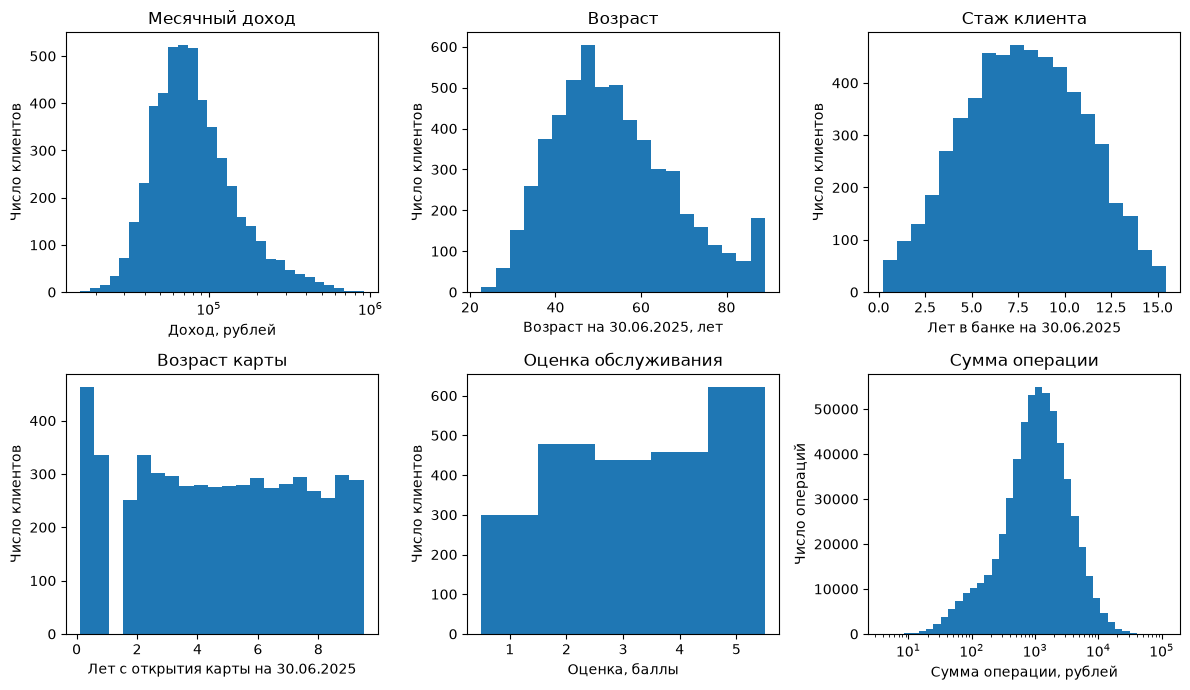

In [188]:
as_of = pd.Timestamp("2025-06-30")
observed = ~clients["income_imputed"] & ~clients["false_income"]
income = clients.loc[observed, "monthly_income"]
age = (as_of - clients["birth_date"]).dt.days / 365.25
tenure = (as_of - clients["registration_date"]).dt.days / 365.25
card_age = (as_of - clients["card_open_date"]).dt.days / 365.25
score = clients["satisfaction_score"].dropna()
purchases = transactions.loc[
    (transactions["amount"] > 0) & (transactions["currency"] == "RUB"),
    "amount",
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

income_bins = np.logspace(np.log10(income.min()), np.log10(income.max()), 30)
axes[0, 0].hist(income, bins=income_bins)
axes[0, 0].set_xscale("log")
axes[0, 0].set_xlabel("Доход, рублей")
axes[0, 0].set_ylabel("Число клиентов")
axes[0, 0].set_title("Месячный доход")

axes[0, 1].hist(age, bins=20)
axes[0, 1].set_xlabel("Возраст на 30.06.2025, лет")
axes[0, 1].set_ylabel("Число клиентов")
axes[0, 1].set_title("Возраст")

axes[0, 2].hist(tenure, bins=20)
axes[0, 2].set_xlabel("Лет в банке на 30.06.2025")
axes[0, 2].set_ylabel("Число клиентов")
axes[0, 2].set_title("Стаж клиента")

axes[1, 0].hist(card_age, bins=20)
axes[1, 0].set_xlabel("Лет с открытия карты на 30.06.2025")
axes[1, 0].set_ylabel("Число клиентов")
axes[1, 0].set_title("Возраст карты")

axes[1, 1].hist(score, bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5])
axes[1, 1].set_xticks([1, 2, 3, 4, 5])
axes[1, 1].set_xlabel("Оценка, баллы")
axes[1, 1].set_ylabel("Число клиентов")
axes[1, 1].set_title("Оценка обслуживания")

amount_bins = np.logspace(np.log10(purchases.min()), np.log10(purchases.max()), 40)
axes[1, 2].hist(purchases, bins=amount_bins)
axes[1, 2].set_xscale("log")
axes[1, 2].set_xlabel("Сумма операции, рублей")
axes[1, 2].set_ylabel("Число операций")
axes[1, 2].set_title("Сумма операции")

fig.tight_layout()
plt.show()


In [189]:
def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

print(
    f"Доход, {len(income)} исходных значений: медиана {income.median():.0f} рублей, "
    f"межквартильный размах {iqr(income):.0f} рублей, среднее {income.mean():.0f}"
)
print(
    f"Сумма операции, {len(purchases)} положительных в рублях, 2024-01-01 .. 2025-06-30: "
    f"медиана {purchases.median():.0f} рублей, межквартильный размах {iqr(purchases):.0f} рублей, "
    f"среднее {purchases.mean():.0f}"
)
print(
    f"Возраст на 30.06.2025, {len(age)} клиентов: среднее {age.mean():.1f} лет, "
    f"медиана {age.median():.1f}, стандартное отклонение {age.std():.1f}, "
    f"минимум {age.min():.1f}, максимум {age.max():.1f}"
)
print(
    f"Стаж, {len(tenure)} клиентов: среднее {tenure.mean():.1f} лет, "
    f"медиана {tenure.median():.1f}, стандартное отклонение {tenure.std():.1f}"
)
print(
    f"Возраст карты, {len(card_age)} клиентов: среднее {card_age.mean():.1f} лет, "
    f"медиана {card_age.median():.1f}, стандартное отклонение {card_age.std():.1f}"
)
print(f"Оценка, ответили {len(score)} из {len(clients)}")
print(score.value_counts().sort_index())


Доход, 4865 исходных значений: медиана 75000 рублей, межквартильный размах 58600 рублей, среднее 99633
Сумма операции, 583869 положительных в рублях, 2024-01-01 .. 2025-06-30: медиана 1097 рублей, межквартильный размах 1805 рублей, среднее 1925
Возраст на 30.06.2025, 5626 клиентов: среднее 53.7 лет, медиана 51.8, стандартное отклонение 14.1, минимум 22.7, максимум 88.9
Стаж, 5626 клиентов: среднее 7.8 лет, медиана 7.8, стандартное отклонение 3.2
Возраст карты, 5626 клиентов: среднее 4.8 лет, медиана 4.8, стандартное отклонение 2.7
Оценка, ответили 2297 из 5626
satisfaction_score
1.0    300
2.0    478
3.0    438
4.0    458
5.0    623
Name: count, dtype: int64


### 5.2. Частотные характеристики категориальных признаков

In [190]:
def frequencies(frame, columns, unit):
    n = len(frame)
    for col in columns:
        counts = frame[col].value_counts(dropna=False)
        table = pd.DataFrame({"n": counts, "доля": (counts / n).round(3)})
        print(f"\n{col}: {n} {unit}")
        print(table.to_string())

frequencies(
    clients,
    [
        "gender",
        "city",
        "segment",
        "loyalty_tier",
        "card_type",
        "income_source",
        "has_mobile_app",
        "marketing_opt_in",
    ],
    "клиентов",
)
print(f"\nbranch_code: {clients['branch_code'].nunique()} кодов отделений из {len(clients)} клиентов")

frequencies(
    transactions,
    ["category", "channel", "status", "currency"],
    "операций",
)



gender: 5626 клиентов
           n   доля
gender             
М       2816  0.501
Ж       2810  0.499

city: 5626 клиентов
                    n   доля
city                        
Москва           1583  0.281
Санкт-Петербург   927  0.165
Екатеринбург      921  0.164
Казань            762  0.135
Нижний Новгород   724  0.129
Новосибирск       697  0.124
Неопределено       12  0.002

segment: 5626 клиентов
                 n   доля
segment                  
Массовый      2900  0.515
Зарплатный    1570  0.279
Премиальный    891  0.158
Private        251  0.045
Неопределено    14  0.002

loyalty_tier: 5626 клиентов
                 n   доля
loyalty_tier             
Базовый       2859  0.508
Серебро       1543  0.274
Золото         916  0.163
Платина        308  0.055

card_type: 5626 клиентов
                n   доля
card_type               
Дебетовая    3932  0.699
Кредитная    1192  0.212
Премиальная   502  0.089

income_source: 5626 клиентов
                            n   доля
income

### 5.3. Динамика по месяцам

In [191]:
ok = transactions.loc[transactions["status"] == "успешно"].copy()
ok["month"] = ok["txn_datetime"].dt.to_period("M").dt.to_timestamp()
months = pd.date_range("2024-01-01", "2025-06-01", freq="MS")

attrs = clients[
    [
        "client_id", "loyalty_tier", "segment", "satisfaction_score",
        "monthly_income", "income_imputed", "false_income",
        "has_mobile_app", "card_type", "city", "gender", "marketing_opt_in",
    ]
].copy()
attrs["satisfaction"] = attrs["satisfaction_score"].map(
    lambda x: str(int(x)) if pd.notna(x) else "нет оценки"
)
observed = ~attrs["income_imputed"] & ~attrs["false_income"]
attrs["income_group"] = "доход подставлен"
attrs.loc[observed, "income_group"] = pd.cut(
    attrs.loc[observed, "monthly_income"],
    [0, 50000, 100000, 200000, np.inf],
    labels=["до 50 тыс.", "50–100 тыс.", "100–200 тыс.", "свыше 200 тыс."],
    right=False,
).astype(str)
linked = ok.merge(attrs, on="client_id", how="left")


def monthly_counts(frame, column=None):
    if column is None:
        return frame.groupby("month").size().reindex(months, fill_value=0)
    table = frame.groupby(["month", column]).size().unstack(column)
    return table.reindex(months, fill_value=0)


def per_client(column, order=None, drop=()):
    counts = monthly_counts(linked, column)
    sizes = attrs[column].value_counts()
    rates = counts.div(sizes, axis=1)
    columns = [c for c in (order or rates.columns) if c in rates.columns and c not in drop]
    return rates[columns]



def monthly_sum(frame, column=None):
    rub = frame.loc[(frame["amount"] > 0) & (frame["currency"] == "RUB")]
    if column is None:
        return rub.groupby("month")["amount"].sum().reindex(months, fill_value=0)
    table = rub.groupby(["month", column])["amount"].sum().unstack(column)
    return table.reindex(months, fill_value=0)


def per_client_sum(column, order=None, drop=()):
    sums = monthly_sum(linked, column)
    sizes = attrs[column].value_counts()
    rates = sums.div(sizes, axis=1)
    columns = [c for c in (order or rates.columns) if c in rates.columns and c not in drop]
    return rates[columns]


def period_change(table):
    base = table.loc[table.index < "2025-01-01"].mean()
    later = table.loc[table.index >= "2025-01-01"].mean()
    pct = (later - base) / base * 100
    if isinstance(pct, pd.Series):
        print(pct.sort_values().round(1).to_string())
    else:
        print(round(float(pct), 1))


def draw(table, ylabel, title):
    fig, ax = plt.subplots(figsize=(11, 4))
    if isinstance(table, pd.Series):
        ax.plot(table.index, table.values, marker="o", markersize=3)
    else:
        for col in table.columns:
            ax.plot(table.index, table[col], marker="o", markersize=3, label=col)
        ax.legend(fontsize=8)
    ax.axvline(pd.Timestamp("2025-01-01"), color="0.5", linestyle="--", linewidth=1)
    ax.set_xlabel("Месяц")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(months)
    ax.set_xticklabels([d.strftime("%Y-%m") for d in months], rotation=45, ha="right")
    fig.tight_layout()
    plt.show()
    period_change(table)



Линии — успешные операции. Пунктир — январь 2025, начало оцениваемого периода. Сравнение: средний месяц 2024 года и средний месяц января–июня 2025. По категориям и каналам это число операций. По признакам клиента — операций на одного клиента группы, чтобы большая группа не казалась активнее только из-за размера. «Неопределено» на графиках нет: город у 12 клиентов, сегмент у 14.


Успешные операции в месяц, изменение среднего месяца 2025 к 2024, %


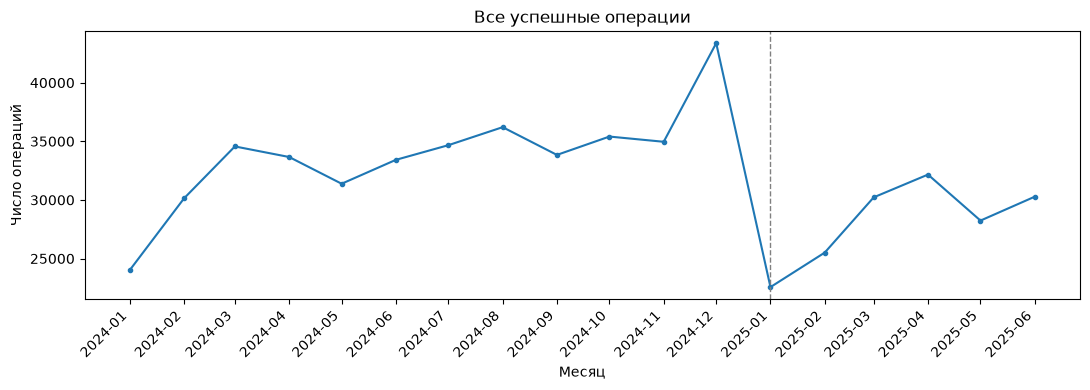

-16.7


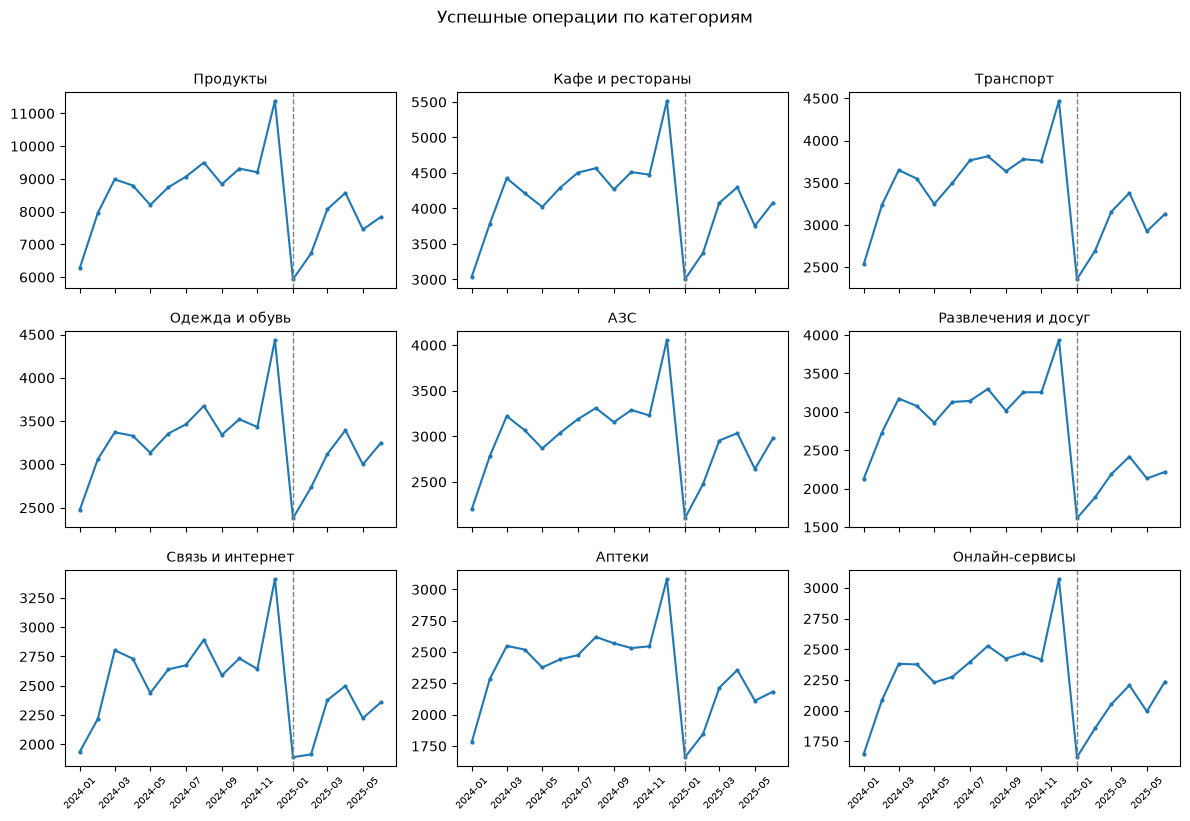

Категории, изменение между базовым и оцениваемым периодом, %
category
Развлечения и досуг   -32.6
Транспорт             -17.8
Аптеки                -16.9
Связь и интернет      -16.4
Продукты              -16.1
Онлайн-сервисы        -15.4
АЗС                   -13.5
Кафе и рестораны      -12.5
Одежда и обувь        -11.9


In [192]:
total = monthly_counts(ok)
print("Успешные операции в месяц, изменение среднего месяца 2025 к 2024, %")
draw(total, "Число операций", "Все успешные операции")

categories = monthly_counts(ok, "category")
categories = categories[categories.mean().sort_values(ascending=False).index]
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
for ax, col in zip(axes.ravel(), categories.columns):
    ax.plot(categories.index, categories[col], marker="o", markersize=2)
    ax.axvline(pd.Timestamp("2025-01-01"), color="0.5", linestyle="--", linewidth=1)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
fig.suptitle("Успешные операции по категориям", y=1.02)
fig.tight_layout()
plt.show()
print("Категории, изменение между базовым и оцениваемым периодом, %")
period_change(categories)


Всего успешных операций в месяц: 33804 в 2024 и 28162 в январе–июне 2025, минус 16,7%.

Категории падают все. Сильнее всего развлечения и досуг, минус 32,6%. Транспорт минус 17,8%, аптеки 16,9%, связь 16,4%, продукты 16,1%, онлайн-сервисы 15,4%, АЗС 13,5%, кафе 12,5%, одежда 11,9%.


Сумма успешных операций в рублях, изменение среднего месяца 2025 к 2024, %


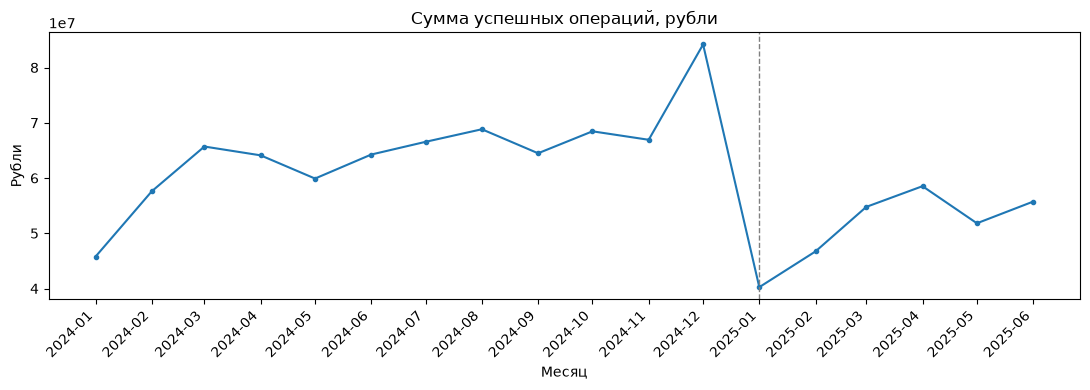

-20.7
Средний чек, изменение, %


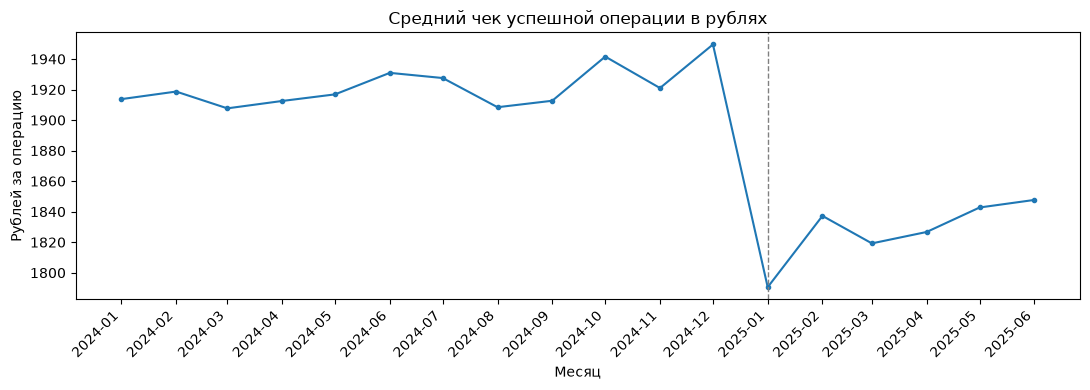

-4.9
Клиенты с хотя бы одной успешной операцией, изменение, %


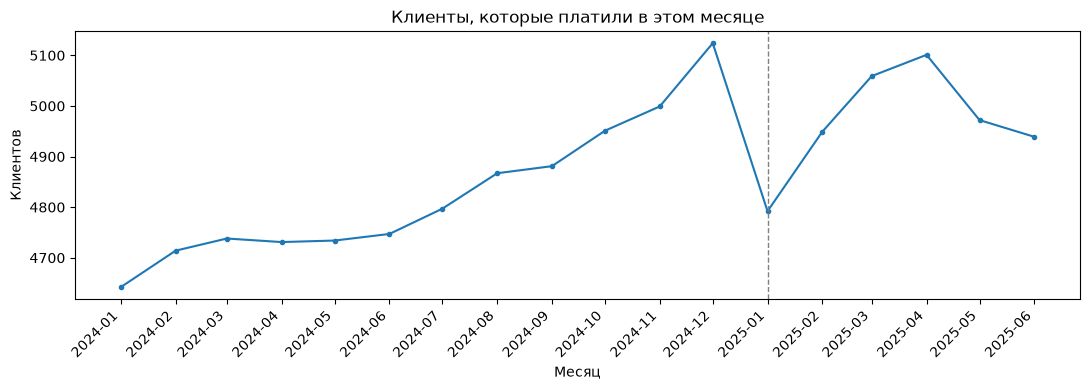

2.9
         операций      рублей     чек  клиентов
2024-01     24025  45787812.0  1914.0      4642
2024-12     43369  84174712.0  1950.0      5124
2025-01     22565  40244634.0  1791.0      4792
2025-06     30277  55730196.0  1848.0      4939
Категории, сумма в рублях, изменение среднего месяца, %
category
Развлечения и досуг   -36.1
Связь и интернет      -22.3
Транспорт             -22.1
Онлайн-сервисы        -21.2
Аптеки                -20.8
Продукты              -20.4
АЗС                   -17.3
Кафе и рестораны      -16.5
Одежда и обувь        -15.5
Доля категорий в разнице суммы января 2025 и января 2024, %
category
Развлечения и досуг    35.9
Одежда и обувь         26.2
Продукты               15.4
Кафе и рестораны        6.5
АЗС                     6.3
Аптеки                  3.9
Онлайн-сервисы          2.6
Связь и интернет        2.4
Транспорт               0.8


In [193]:
print("Сумма успешных операций в рублях, изменение среднего месяца 2025 к 2024, %")
draw(monthly_sum(ok), "Рубли", "Сумма успешных операций, рубли")

ticket = (
    ok.loc[(ok["amount"] > 0) & (ok["currency"] == "RUB")]
    .groupby("month")["amount"]
    .mean()
    .reindex(months)
)
print("Средний чек, изменение, %")
draw(ticket, "Рублей за операцию", "Средний чек успешной операции в рублях")

active = ok.groupby("month")["client_id"].nunique().reindex(months)
print("Клиенты с хотя бы одной успешной операцией, изменение, %")
draw(active, "Клиентов", "Клиенты, которые платили в этом месяце")

shape = pd.DataFrame({
    "операций": monthly_counts(ok),
    "рублей": monthly_sum(ok).round(0),
    "чек": ticket.round(0),
    "клиентов": active,
})
picked = shape.loc[["2024-01-01", "2024-12-01", "2025-01-01", "2025-06-01"]].copy()
picked.index = picked.index.strftime("%Y-%m")
print(picked.to_string())

cat_sum = monthly_sum(ok, "category")
print("Категории, сумма в рублях, изменение среднего месяца, %")
period_change(cat_sum)
gap = cat_sum.iloc[0] - cat_sum.loc["2025-01-01"]
print("Доля категорий в разнице суммы января 2025 и января 2024, %")
print((gap / gap.sum() * 100).sort_values(ascending=False).round(1).to_string())


Сумма в рублях падает сильнее числа операций: средний месяц января–июня минус 20,7% к среднему месяцу 2024, операции минус 16,7%. Декабрь выше среднего месяца 2024 примерно на 28% по операциям и на 30% по рублям. Январь 2024 тоже низкий. К нему январь 2025 — 94% операций и 88% рублей. Июнь выше января 2024 (126% операций и 122% рублей), но ниже обычного месяца 2024.

Чек весь 2024 держится около 1910–1950 рублей, в январе 2025 падает до 1791 и остаётся около 1830–1850. Платили в январе 2025: 4792 клиента, в январе 2024: 4642.

Разница сумм января 2025 и января 2024: развлечения 36%, одежда 26%, продукты 15%. По среднему месяцу сильнее всех падают рубли развлечений, минус 36%.


Средний чек 2024: 1922.6
Средний чек 2025: 1828.6
Смена долей категорий, рублей: -2.6
Смена чека внутри категорий, рублей: -92.1
                     доля 2024, %  доля 2025, %  чек 2024  чек 2025  чек, %
category                                                                   
Связь и интернет              7.8           7.9     808.9     750.5    -7.2
Онлайн-сервисы                7.0           7.1     678.6     632.2    -6.8
Развлечения и досуг           9.1           7.4    3470.9    3291.6    -5.2
Продукты                     26.2          26.4    1316.3    1248.5    -5.1
Транспорт                    10.6          10.4     132.2     125.4    -5.1
Аптеки                        7.3           7.3    1072.5    1021.5    -4.8
Кафе и рестораны             12.7          13.4    2102.6    2006.7    -4.6
АЗС                           9.2           9.6    2489.4    2377.3    -4.5
Одежда и обувь               10.0          10.6    5603.1    5371.7    -4.1


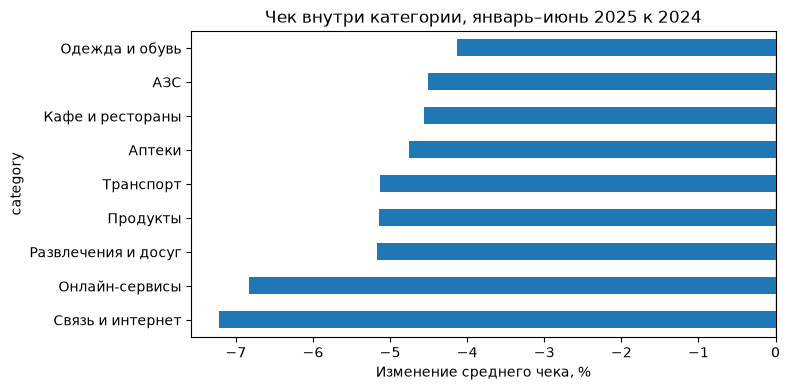

медиана 1114 -> 1026 , -7.9 %
99-й перцентиль 12538 -> 12429 , -0.9 %


In [194]:
rub = ok.loc[(ok["amount"] > 0) & (ok["currency"] == "RUB")].copy()
rub["half"] = np.where(rub["month"] < "2025-01-01", "2024", "2025")
grouped = rub.groupby(["half", "category"])["amount"].agg(n="size", ticket="mean")
base, later = grouped.loc["2024"], grouped.loc["2025"]
share_b = base["n"] / base["n"].sum()
share_l = later["n"] / later["n"].sum()
mix = ((share_l - share_b) * base["ticket"]).sum()
within = (share_b * (later["ticket"] - base["ticket"])).sum()
print("Средний чек 2024:", round(base["n"].dot(base["ticket"]) / base["n"].sum(), 1))
print("Средний чек 2025:", round(later["n"].dot(later["ticket"]) / later["n"].sum(), 1))
print("Смена долей категорий, рублей:", round(mix, 1))
print("Смена чека внутри категорий, рублей:", round(within, 1))

view = pd.DataFrame({
    "доля 2024, %": share_b * 100,
    "доля 2025, %": share_l * 100,
    "чек 2024": base["ticket"],
    "чек 2025": later["ticket"],
    "чек, %": (later["ticket"] / base["ticket"] - 1) * 100,
}).sort_values("чек, %")
print(view.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
view["чек, %"].sort_values().plot.barh(ax=ax)
ax.axvline(0, color="0.5", linewidth=1)
ax.set_xlabel("Изменение среднего чека, %")
ax.set_title("Чек внутри категории, январь–июнь 2025 к 2024")
fig.tight_layout()
plt.show()

for name, q in [("медиана", 0.5), ("99-й перцентиль", 0.99)]:
    before = rub.loc[rub["half"] == "2024", "amount"].quantile(q)
    after = rub.loc[rub["half"] == "2025", "amount"].quantile(q)
    print(name, round(before), "->", round(after), ",", round((after / before - 1) * 100, 1), "%")


Средний чек успешной рублёвой операции: 1923 в 2024 и 1829 в январе–июне 2025, минус 94 рубля. Медиана падает сильнее, с 1114 до 1026, минус 7,9%. 99-й перцентиль 12538 и 12429.

Из этих 94 рублей смена долей категорий даёт минус 2.6, чек внутри категорий — минус 92. Доля развлечений в операциях ниже на 1,7 пункта, доля одежды и кафе чуть выше, вместе это почти ноль. Внутри каждой категории чек ниже на 4–7%.


Каналы, изменение, %


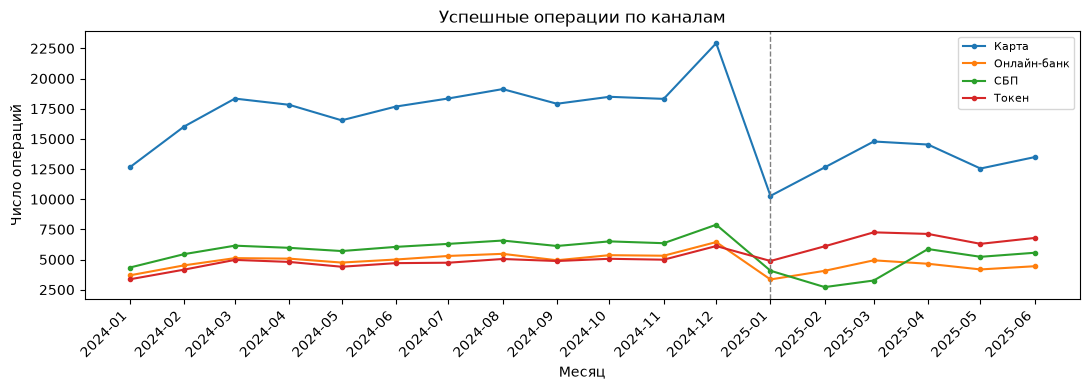

channel
СБП           -27.2
Карта         -26.9
Онлайн-банк   -16.0
Токен          34.4
Каналы, сумма в рублях, изменение, %


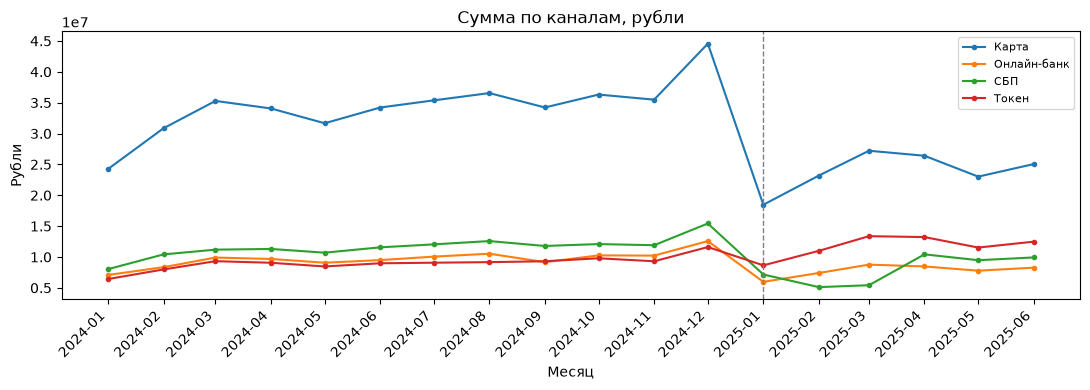

channel
СБП           -31.6
Карта         -30.6
Онлайн-банк   -19.8
Токен          29.5


In [195]:
print("Каналы, изменение, %")
draw(monthly_counts(ok, "channel"), "Число операций", "Успешные операции по каналам")

print("Каналы, сумма в рублях, изменение, %")
draw(monthly_sum(ok, "channel"), "Рубли", "Сумма по каналам, рубли")


Каналы расходятся. Карта минус 26,9%, СБП минус 27,2%, онлайн-банк минус 16,0%. Токен плюс 34,4%.

В каналах рубли повторяют операции: карта минус 31%, СБП минус 32%, онлайн-банк минус 20%, токен плюс 30%.


Лояльность, операций на клиента, изменение, %


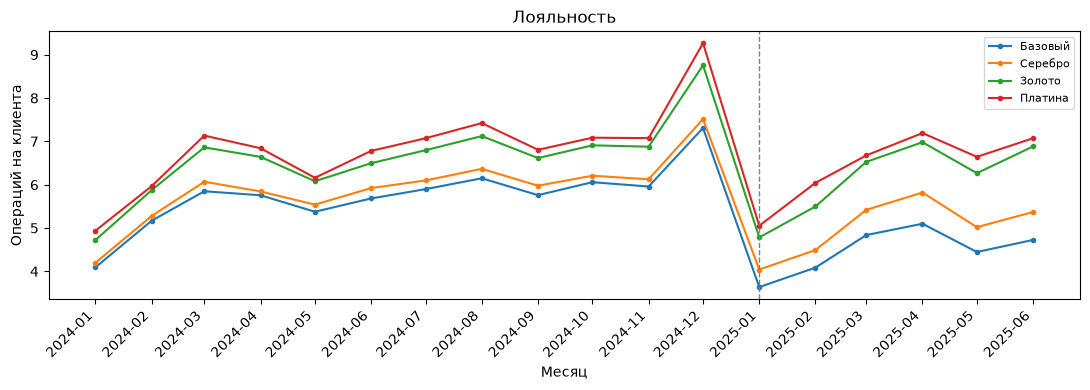

loyalty_tier
Базовый   -22.3
Серебро   -15.2
Золото     -7.4
Платина    -6.3
Лояльность, рублей на клиента, изменение, %


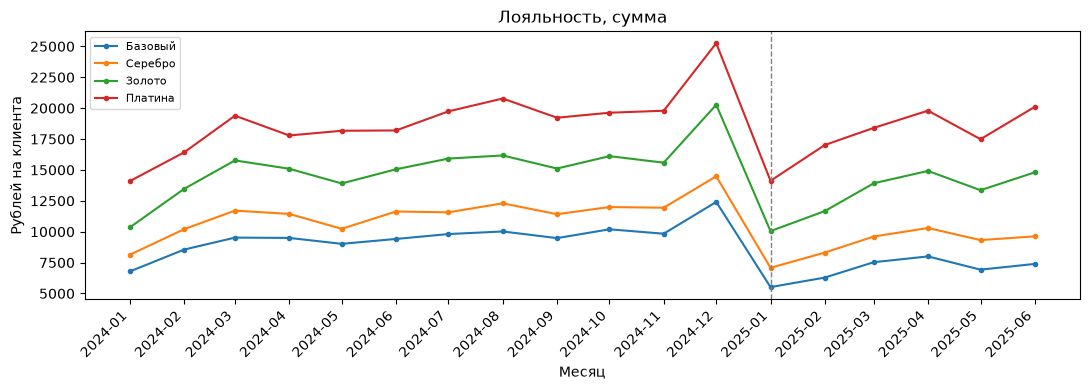

loyalty_tier
Базовый   -27.3
Серебро   -20.9
Золото    -13.9
Платина    -6.4
Сегмент, операций на клиента, изменение, %


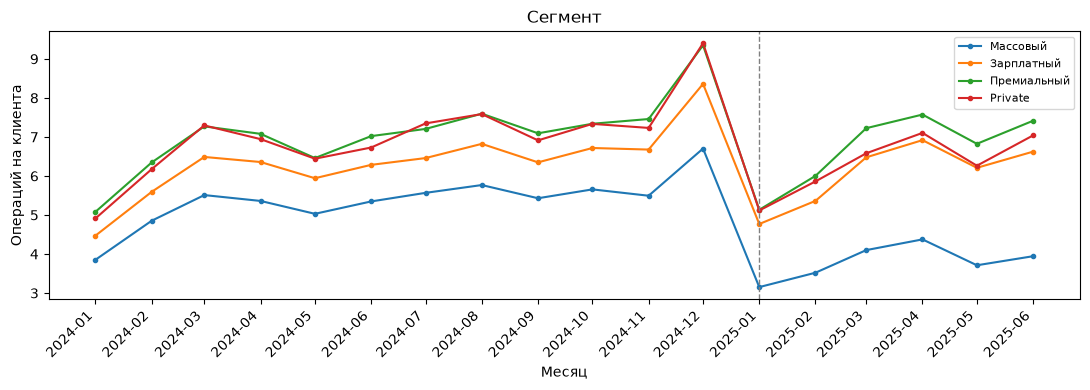

segment
Массовый      -29.4
Private        -9.9
Премиальный    -5.8
Зарплатный     -5.0
Сегмент, рублей на клиента, изменение, %


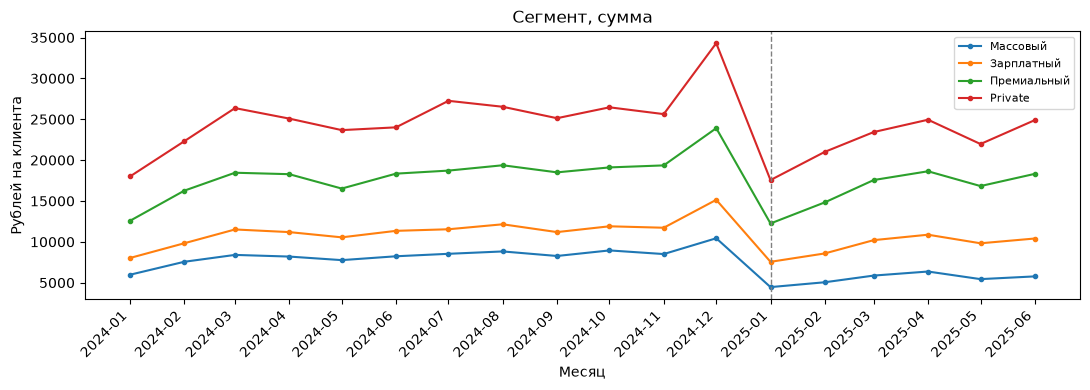

segment
Массовый      -33.8
Зарплатный    -15.6
Private       -12.2
Премиальный   -10.3
Оценка, операций на клиента, изменение, %


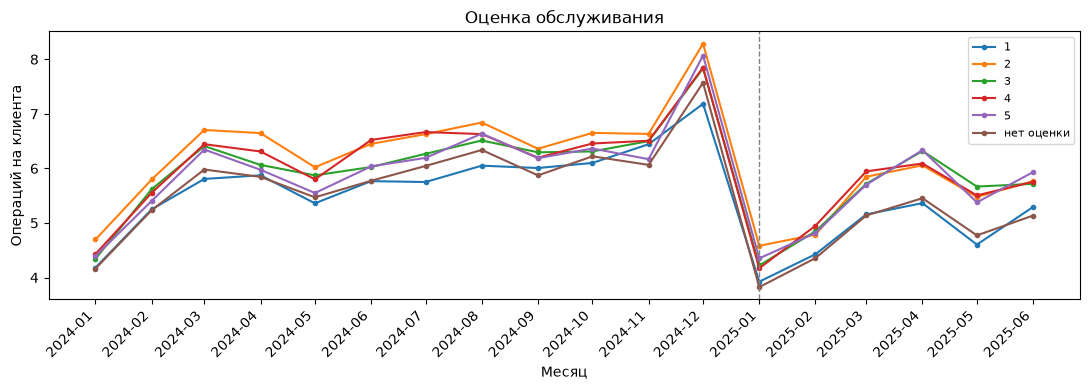

satisfaction
нет оценки   -18.7
1            -17.5
2            -16.3
4            -14.0
3            -12.2
5            -11.3
Доход, операций на клиента, изменение, %


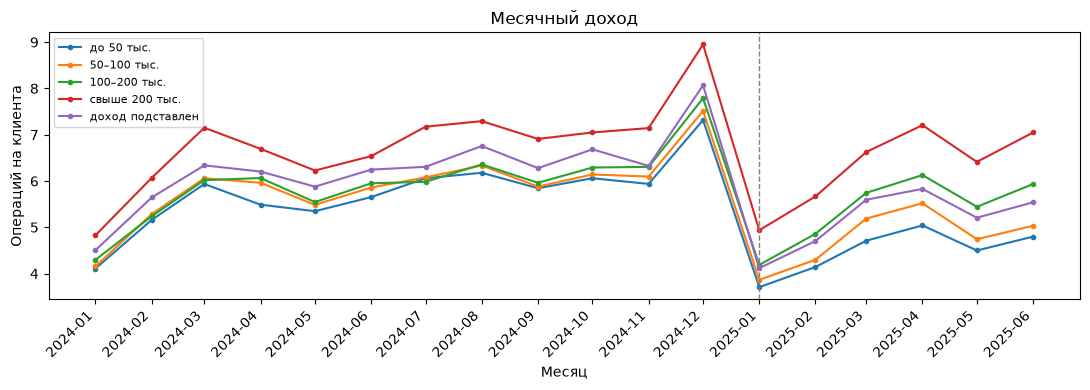

income_group
до 50 тыс.         -22.1
50–100 тыс.        -19.1
доход подставлен   -17.6
100–200 тыс.       -10.0
свыше 200 тыс.      -7.6
Доход, рублей на клиента, изменение, %


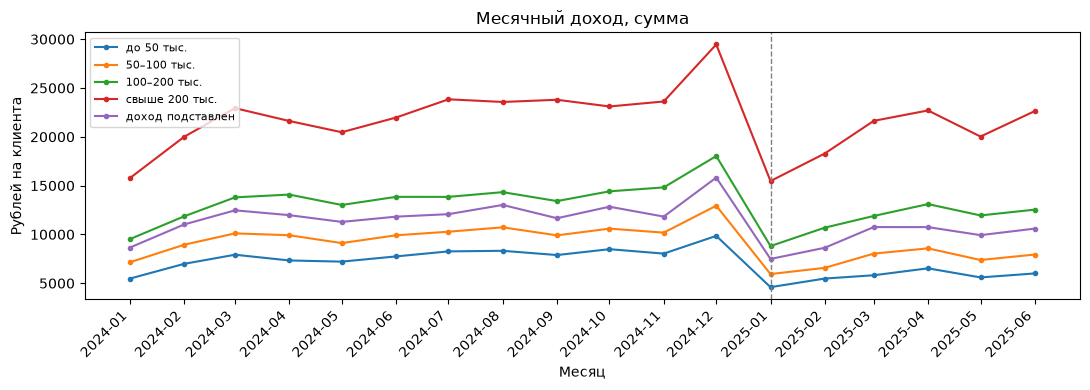

income_group
до 50 тыс.         -27.3
50–100 тыс.        -25.8
доход подставлен   -19.5
100–200 тыс.       -16.4
свыше 200 тыс.     -10.6


In [196]:
print("Лояльность, операций на клиента, изменение, %")
draw(
    per_client("loyalty_tier", ["Базовый", "Серебро", "Золото", "Платина"]),
    "Операций на клиента",
    "Лояльность",
)
print("Лояльность, рублей на клиента, изменение, %")
draw(
    per_client_sum("loyalty_tier", ["Базовый", "Серебро", "Золото", "Платина"]),
    "Рублей на клиента",
    "Лояльность, сумма",
)
print("Сегмент, операций на клиента, изменение, %")
draw(
    per_client("segment", ["Массовый", "Зарплатный", "Премиальный", "Private"], drop=("Неопределено",)),
    "Операций на клиента",
    "Сегмент",
)
print("Сегмент, рублей на клиента, изменение, %")
draw(
    per_client_sum("segment", ["Массовый", "Зарплатный", "Премиальный", "Private"], drop=("Неопределено",)),
    "Рублей на клиента",
    "Сегмент, сумма",
)
print("Оценка, операций на клиента, изменение, %")
draw(
    per_client("satisfaction", ["1", "2", "3", "4", "5", "нет оценки"]),
    "Операций на клиента",
    "Оценка обслуживания",
)
print("Доход, операций на клиента, изменение, %")
draw(
    per_client(
        "income_group",
        ["до 50 тыс.", "50–100 тыс.", "100–200 тыс.", "свыше 200 тыс.", "доход подставлен"],
    ),
    "Операций на клиента",
    "Месячный доход",
)
print("Доход, рублей на клиента, изменение, %")
draw(
    per_client_sum(
        "income_group",
        ["до 50 тыс.", "50–100 тыс.", "100–200 тыс.", "свыше 200 тыс.", "доход подставлен"],
    ),
    "Рублей на клиента",
    "Месячный доход, сумма",
)


Лояльность: Базовый минус 22,3% операций на клиента, Серебро 15,2%, Золото 7,4%, Платина 6,3%. Сегмент: Массовый минус 29,4%, Private 9,9%, Премиальный 5,8%, Зарплатный 5,0%.

Доход, без подставленных значений: до 50 тыс. минус 22,1%, 50–100 тыс. минус 19,1%, 100–200 тыс. минус 10,0%, свыше 200 тыс. минус 7,6%. Подставленный доход, 761 клиент, минус 17,6%. Оценка: без ответа минус 18,7%, оценка 1 минус 17,5%, оценка 5 минус 11,3%.

Средний месяц 2025 к 2024 по рублям на клиента: массовый минус 34%, базовый минус 27%, доход до 50 тыс. минус 27%. Платина минус 6%, премиальный минус 10%, Private минус 12%, доход свыше 200 тыс. минус 11%.


Приложение, операций на клиента, изменение, %


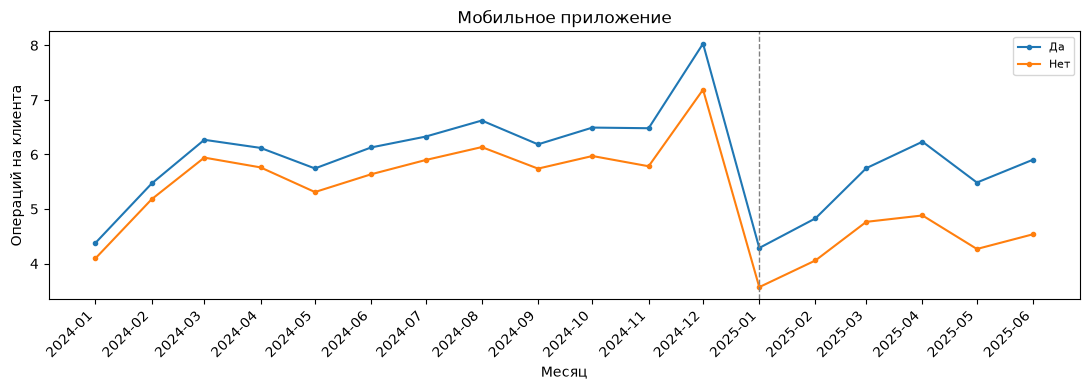

has_mobile_app
Нет   -24.0
Да    -12.5
Тип карты, операций на клиента, изменение, %


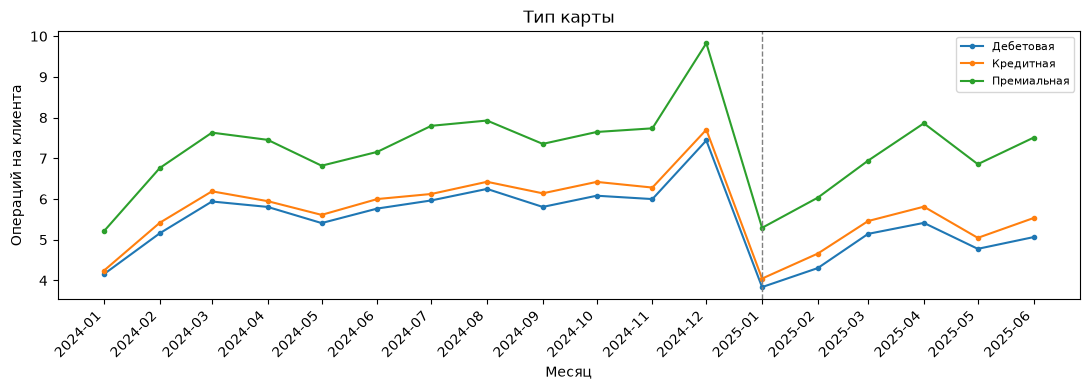

card_type
Дебетовая     -18.2
Кредитная     -15.7
Премиальная    -9.3
Город, операций на клиента, изменение, %


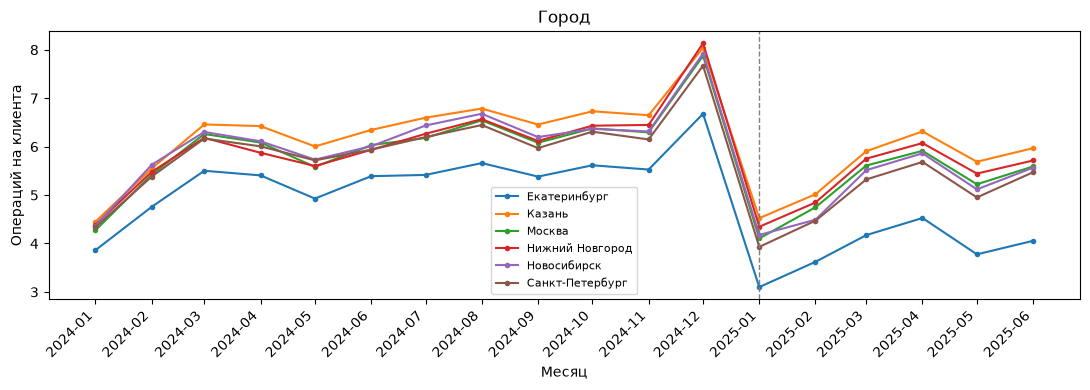

city
Екатеринбург      -27.5
Санкт-Петербург   -17.5
Новосибирск       -17.0
Москва            -14.6
Казань            -12.6
Нижний Новгород   -12.4
Пол, операций на клиента, изменение, %


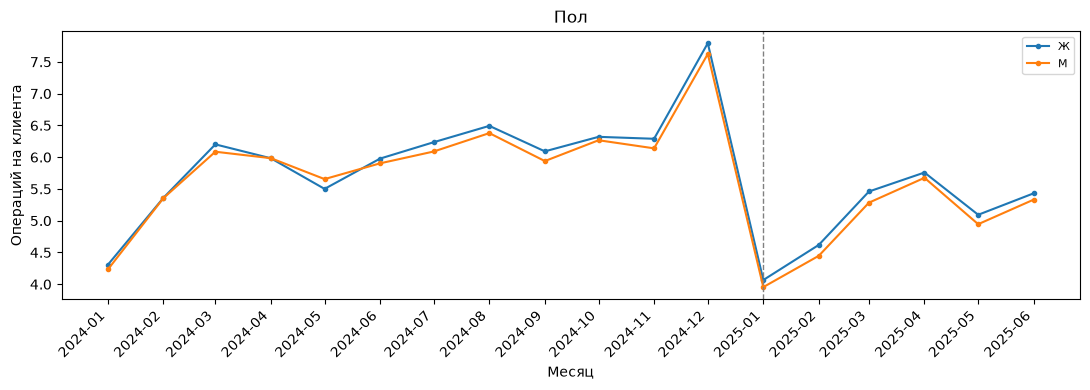

gender
М   -17.3
Ж   -16.1
Согласие на коммуникацию, операций на клиента, изменение, %


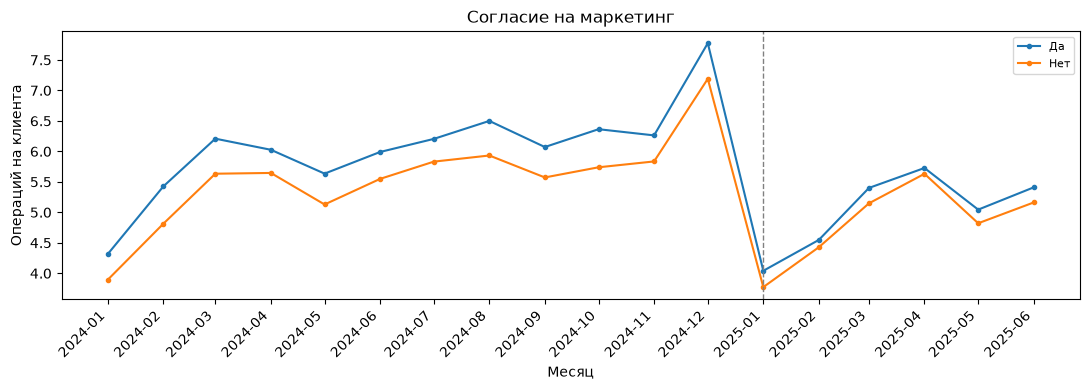

marketing_opt_in
Да    -17.1
Нет   -13.2


In [197]:
print("Приложение, операций на клиента, изменение, %")
draw(per_client("has_mobile_app"), "Операций на клиента", "Мобильное приложение")
print("Тип карты, операций на клиента, изменение, %")
draw(per_client("card_type"), "Операций на клиента", "Тип карты")
print("Город, операций на клиента, изменение, %")
draw(per_client("city", drop=("Неопределено",)), "Операций на клиента", "Город")
print("Пол, операций на клиента, изменение, %")
draw(per_client("gender"), "Операций на клиента", "Пол")
print("Согласие на коммуникацию, операций на клиента, изменение, %")
draw(per_client("marketing_opt_in"), "Операций на клиента", "Согласие на маркетинг")


Приложения нет — минус 24,0%, приложение есть — минус 12,5%. Дебетовая карта минус 18,2%, кредитная 15,7%, премиальная 9,3%.

Города: Екатеринбург минус 27,5%, Санкт-Петербург 17,5%, Новосибирск 17,0%, Москва 14,6%, Казань 12,6%, Нижний Новгород 12,4%.

Пол почти не разделяет: мужчины минус 17,3%, женщины минус 16,1%. Согласие на маркетинг тоже близко: да минус 17,1%, нет минус 13,2%.


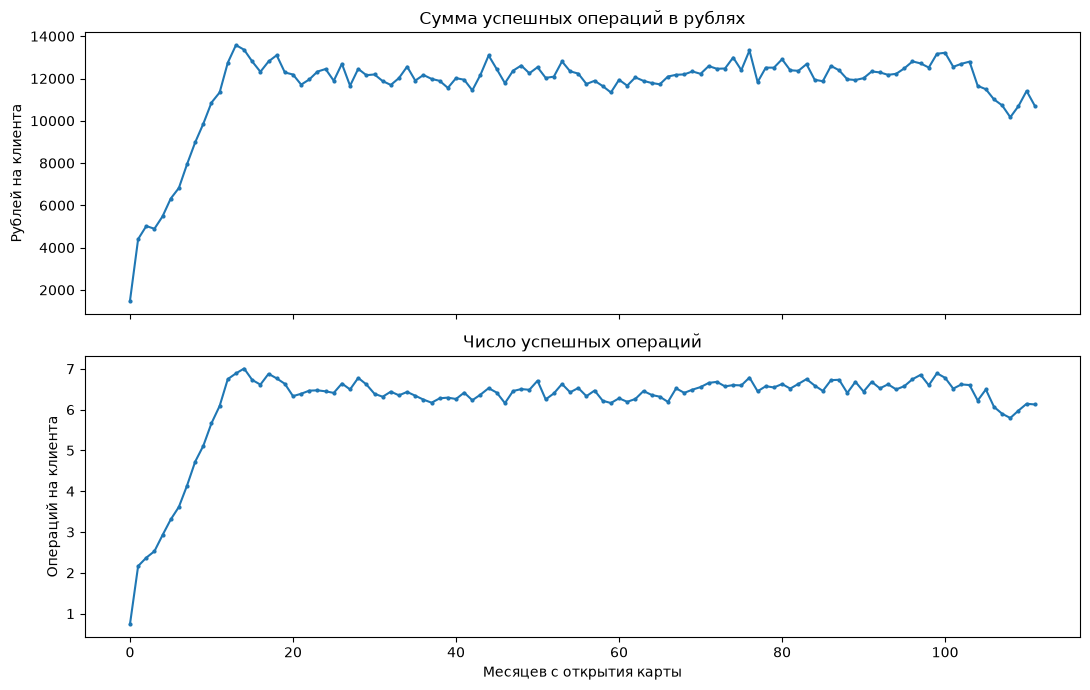

Месяц 0: 0.74 операции, 1487 рублей
Месяц 6: 3.62 операции, 6822 рублей
Месяц 12: 6.75 операции, 12747 рублей


In [198]:
life = ok.merge(clients[["client_id", "card_open_date"]], on="client_id", how="left")
life = life.loc[life["txn_datetime"] >= life["card_open_date"]].copy()
life["tenure"] = (
    (life["txn_datetime"].dt.year - life["card_open_date"].dt.year) * 12
    + (life["txn_datetime"].dt.month - life["card_open_date"].dt.month)
)
base = clients[["client_id", "card_open_date"]].copy()
base["open_m"] = base["card_open_date"].dt.to_period("M").dt.to_timestamp()
grid = base.assign(key=1).merge(pd.DataFrame({"month": months, "key": 1}), on="key")
grid["tenure"] = (
    (grid["month"].dt.year - grid["open_m"].dt.year) * 12
    + (grid["month"].dt.month - grid["open_m"].dt.month)
)
grid = grid.loc[grid["tenure"] >= 0]
exposed = grid.groupby("tenure")["client_id"].nunique()
rub = life.loc[(life["amount"] > 0) & (life["currency"] == "RUB")]
by_tenure = pd.DataFrame({
    "клиентов": exposed,
    "сумма": rub.groupby("tenure")["amount"].sum(),
    "операций": life.groupby("tenure").size(),
}).fillna(0)
by_tenure = by_tenure.loc[by_tenure["клиентов"] >= 150]
by_tenure["сумма на клиента"] = by_tenure["сумма"] / by_tenure["клиентов"]
by_tenure["операций на клиента"] = by_tenure["операций"] / by_tenure["клиентов"]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(by_tenure.index, by_tenure["сумма на клиента"], marker="o", markersize=2)
axes[0].set_ylabel("Рублей на клиента")
axes[0].set_title("Сумма успешных операций в рублях")
axes[1].plot(by_tenure.index, by_tenure["операций на клиента"], marker="o", markersize=2)
axes[1].set_ylabel("Операций на клиента")
axes[1].set_xlabel("Месяцев с открытия карты")
axes[1].set_title("Число успешных операций")
fig.tight_layout()
plt.show()
print(
    "Месяц 0:",
    round(by_tenure.loc[0, "операций на клиента"], 2),
    "операции,",
    round(by_tenure.loc[0, "сумма на клиента"]),
    "рублей",
)
print(
    "Месяц 6:",
    round(by_tenure.loc[6, "операций на клиента"], 2),
    "операции,",
    round(by_tenure.loc[6, "сумма на клиента"]),
    "рублей",
)
print(
    "Месяц 12:",
    round(by_tenure.loc[12, "операций на клиента"], 2),
    "операции,",
    round(by_tenure.loc[12, "сумма на клиента"]),
    "рублей",
)


Срок с открытия карты — другая ось. Нулевой месяц неполный: карта открыта не первого числа, поэтому там около 0,7 операции и 1500 рублей на клиента. К 12-му месяцу выходит примерно на 6,7 операции и 13 тысяч рублей и дальше держится на этом уровне.


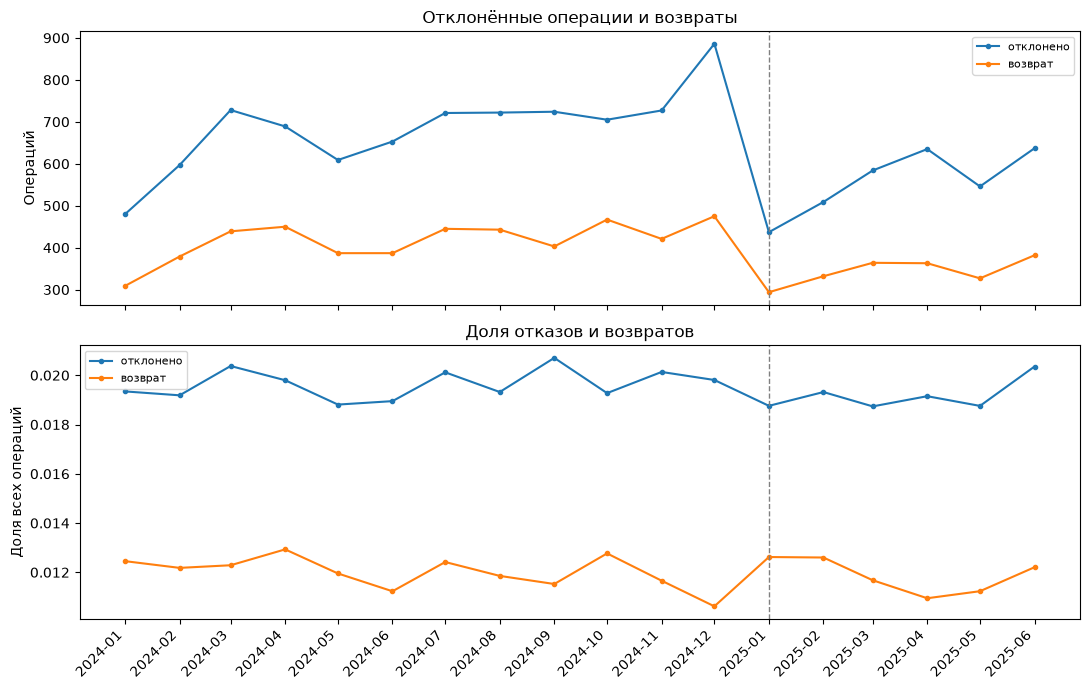

Средняя доля, 2024 и январь–июнь 2025
             2024    2025
status                   
возврат    0.0120  0.0119
отклонено  0.0197  0.0192
успешно    0.9684  0.9689
Сумма возвратов в рублях / сумма успешных рублей, средняя
2024 0.0128
2025 0.0129


In [199]:
flow = transactions.copy()
flow["month"] = flow["txn_datetime"].dt.to_period("M").dt.to_timestamp()
flow = flow.loc[flow["month"].isin(months)]
by_status = flow.groupby(["month", "status"]).size().unstack().reindex(months).fillna(0)
share = by_status.div(by_status.sum(axis=1), axis=0)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for col in ["отклонено", "возврат"]:
    axes[0].plot(by_status.index, by_status[col], marker="o", markersize=3, label=col)
    axes[1].plot(share.index, share[col], marker="o", markersize=3, label=col)
for ax in axes:
    ax.axvline(pd.Timestamp("2025-01-01"), color="0.5", linestyle="--", linewidth=1)
    ax.legend(fontsize=8)
    ax.set_xticks(months)
    ax.set_xticklabels([d.strftime("%Y-%m") for d in months], rotation=45, ha="right")
axes[0].set_ylabel("Операций")
axes[0].set_title("Отклонённые операции и возвраты")
axes[1].set_ylabel("Доля всех операций")
axes[1].set_title("Доля отказов и возвратов")
fig.tight_layout()
plt.show()

print("Средняя доля, 2024 и январь–июнь 2025")
print(pd.DataFrame({
    "2024": share.loc[share.index < "2025-01-01"].mean(),
    "2025": share.loc[share.index >= "2025-01-01"].mean(),
}).round(4).to_string())

ret = flow.loc[(flow["status"] == "возврат") & (flow["currency"] == "RUB")]
succ = flow.loc[(flow["status"] == "успешно") & (flow["currency"] == "RUB") & (flow["amount"] > 0)]
ratio = ret.groupby("month")["amount"].sum().abs() / succ.groupby("month")["amount"].sum()
ratio = ratio.reindex(months)
print("Сумма возвратов в рублях / сумма успешных рублей, средняя")
print("2024", round(ratio.loc[ratio.index < "2025-01-01"].mean(), 4))
print("2025", round(ratio.loc[ratio.index >= "2025-01-01"].mean(), 4))


Отказов около 1,9% операций и в 2024, и в январе–июне 2025. Возвраты около 1,3% суммы успешных рублей. Число отказов повторяет успешные операции.


Пустой app_last_login: 2151
Приложения нет: 2151
Клиентов, чей последний вход пришёлся на месяц


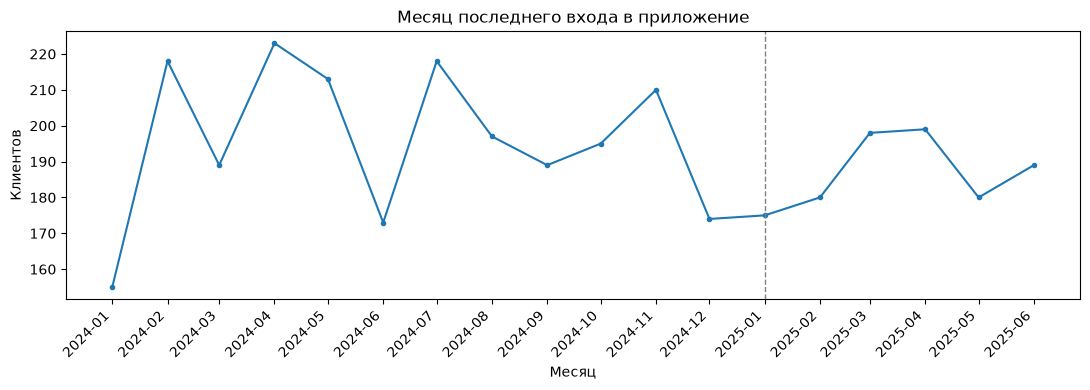

-4.8


In [200]:
login = clients.loc[clients["app_last_login"].notna(), "app_last_login"]
login_month = login.dt.to_period("M").dt.to_timestamp()
last_login = login_month.value_counts().reindex(months, fill_value=0).sort_index()
print("Пустой app_last_login:", int(clients["app_last_login"].isna().sum()))
print("Приложения нет:", int((clients["has_mobile_app"] == "Нет").sum()))
print("Клиентов, чей последний вход пришёлся на месяц")
draw(last_login, "Клиентов", "Месяц последнего входа в приложение")


Помесячных входов в приложение в выгрузке нет. `app_last_login` — месяц последнего входа, одна дата на клиента. Пусто ровно у 2151 клиента без приложения. По месяцу последнего входа люди лежат ровно, около 170–220 в каждый месяц, включая 2025.


MCC, сумма в рублях, изменение среднего месяца, %


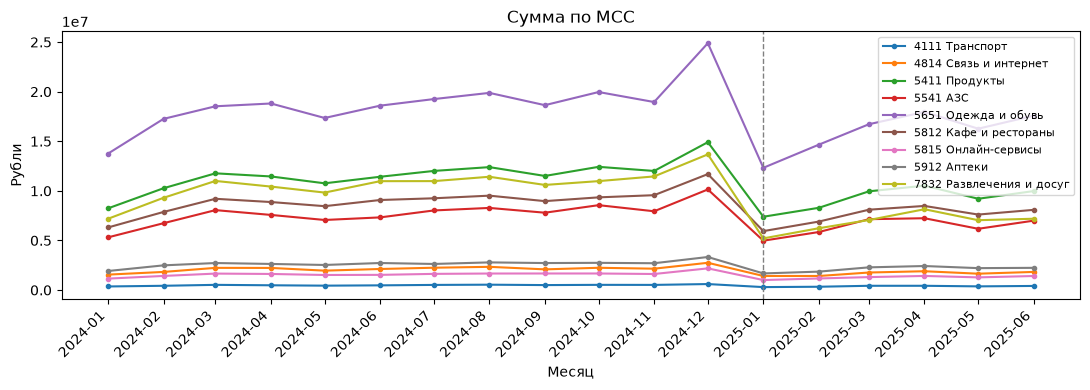

mcc_code
7832 Развлечения и досуг   -36.0
4111 Транспорт             -23.1
4814 Связь и интернет      -22.5
5815 Онлайн-сервисы        -21.5
5912 Аптеки                -20.5
5411 Продукты              -20.5
5541 АЗС                   -17.3
5812 Кафе и рестораны      -16.5
5651 Одежда и обувь        -15.4


In [201]:
mcc_name = ok.groupby("mcc_code")["category"].agg(lambda s: s.mode().iloc[0])
mcc_sum = monthly_sum(ok, "mcc_code").rename(
    columns=lambda code: f"{code} {mcc_name.get(code, '')}"
)
print("MCC, сумма в рублях, изменение среднего месяца, %")
draw(mcc_sum, "Рубли", "Сумма по MCC")


MCC — код типа точки. Кодов девять, и каждый совпадает со своей категорией. Сильнее всех 7832, развлечения, минус 36% рублей. Остальные от минус 15% до минус 23%.


age_group
до 35     392
35–50    2135
50–65    1919
65+      1180
Возраст, рублей на клиента, изменение, %


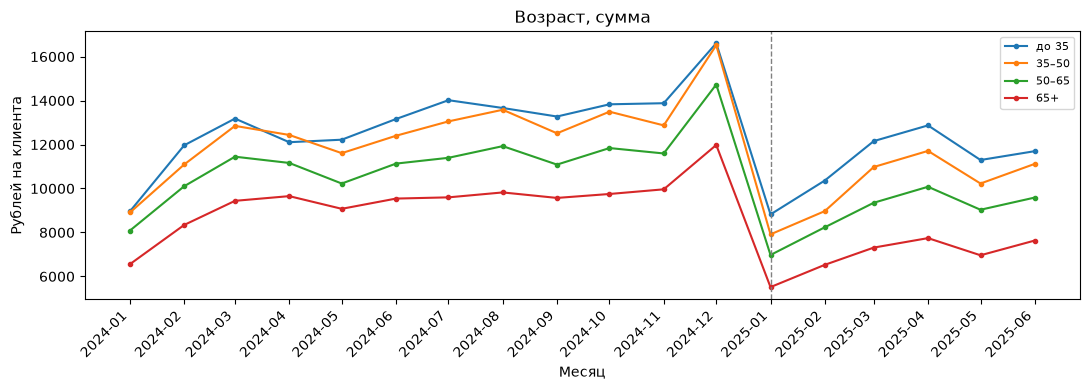

age_group
65+     -26.4
50–65   -20.9
35–50   -19.5
до 35   -14.3


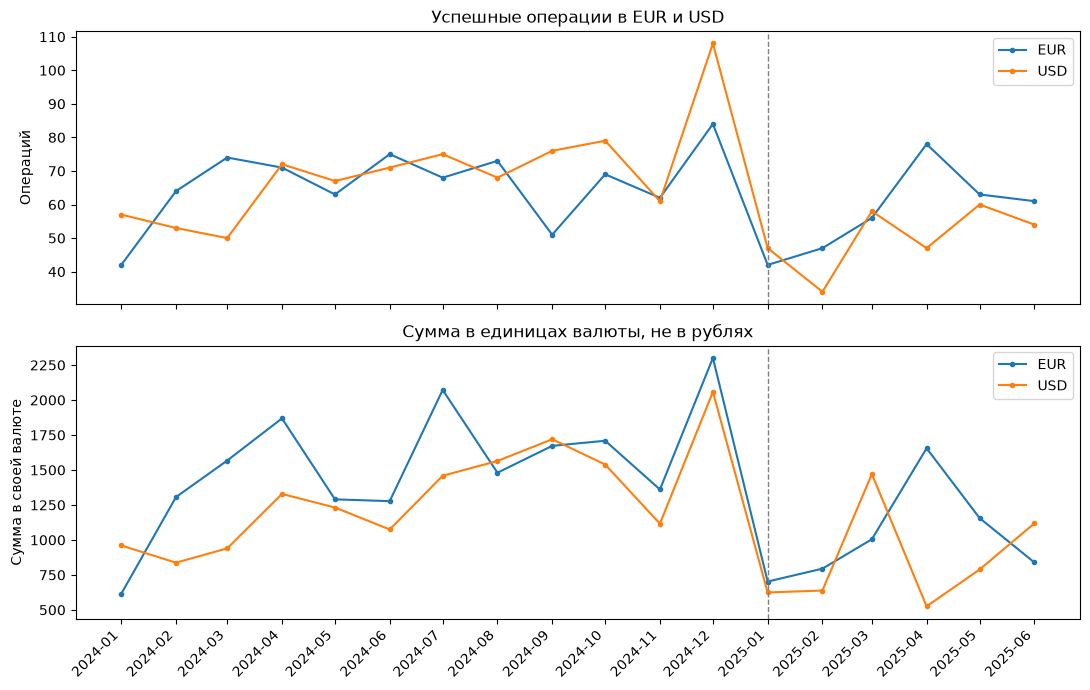

Успешных операций не в рублях: 2280 из 574614
Их сумма, если прибавить к рублям: 45668 против суммы рублей 1084557858
Доля такой добавки: 4.2e-05
Операции, изменение среднего месяца, %
currency
USD   -28.3
EUR   -12.8
Сумма в своей валюте, изменение, %
currency
USD   -34.7
EUR   -33.6


In [202]:
as_of = pd.Timestamp("2025-06-30")
age_map = clients[["client_id"]].copy()
age_map["age_group"] = pd.cut(
    (as_of - clients["birth_date"]).dt.days / 365.25,
    [0, 35, 50, 65, 120],
    labels=["до 35", "35–50", "50–65", "65+"],
    right=False,
)
print(age_map["age_group"].value_counts().sort_index().to_string())
aged = ok.merge(age_map, on="client_id")
age_sum = monthly_sum(aged, "age_group")
age_rate = age_sum.div(age_map["age_group"].value_counts(), axis=1)
print("Возраст, рублей на клиента, изменение, %")
draw(age_rate[["до 35", "35–50", "50–65", "65+"]], "Рублей на клиента", "Возраст, сумма")

fx = ok.loc[ok["currency"].isin(["EUR", "USD"])]
fx_n = fx.groupby(["month", "currency"]).size().unstack().reindex(months).fillna(0)
fx_s = (
    fx.loc[fx["amount"] > 0]
    .groupby(["month", "currency"])["amount"]
    .sum()
    .unstack()
    .reindex(months)
    .fillna(0)
)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for col in ["EUR", "USD"]:
    axes[0].plot(fx_n.index, fx_n[col], marker="o", markersize=3, label=col)
    axes[1].plot(fx_s.index, fx_s[col], marker="o", markersize=3, label=col)
for ax in axes:
    ax.axvline(pd.Timestamp("2025-01-01"), color="0.5", linestyle="--", linewidth=1)
    ax.legend()
    ax.set_xticks(months)
    ax.set_xticklabels([d.strftime("%Y-%m") for d in months], rotation=45, ha="right")
axes[0].set_ylabel("Операций")
axes[0].set_title("Успешные операции в EUR и USD")
axes[1].set_ylabel("Сумма в своей валюте")
axes[1].set_title("Сумма в единицах валюты, не в рублях")
fig.tight_layout()
plt.show()

other = ok.loc[(ok["currency"] != "RUB") & (ok["amount"] > 0), "amount"].sum()
rub_only = ok.loc[(ok["currency"] == "RUB") & (ok["amount"] > 0), "amount"].sum()
print("Успешных операций не в рублях:", int((ok["currency"] != "RUB").sum()), "из", len(ok))
print("Их сумма, если прибавить к рублям:", round(other), "против суммы рублей", round(rub_only))
print("Доля такой добавки:", round(other / rub_only, 6))
print("Операции, изменение среднего месяца, %")
period_change(fx_n)
print("Сумма в своей валюте, изменение, %")
period_change(fx_s)


Возраст падает весь. Рубли на клиента: до 35 лет минус 14%, 35–50 минус 20%, 50–65 минус 21%, 65+ минус 26%. Январь 2025 к январю 2024 у молодых 98%, у 65+ — 84%.

Суммы выше считаются только по рублям и только по положительным успешным операциям. EUR и USD — 2280 успешных операций из 574614. В своих единицах обе валюты в 2025 ниже, но это десятки операций в месяц.


### 5.4. Разрезы и связи между признаками

Клиентов в таблицах: 5612 из 5626
Сегмент и лояльность
loyalty_tier  Базовый  Серебро  Золото  Платина
segment                                        
Массовый         2032      656     180       32
Зарплатный        707      544     282       37
Премиальный       105      308     364      114
Private             6       31      89      125


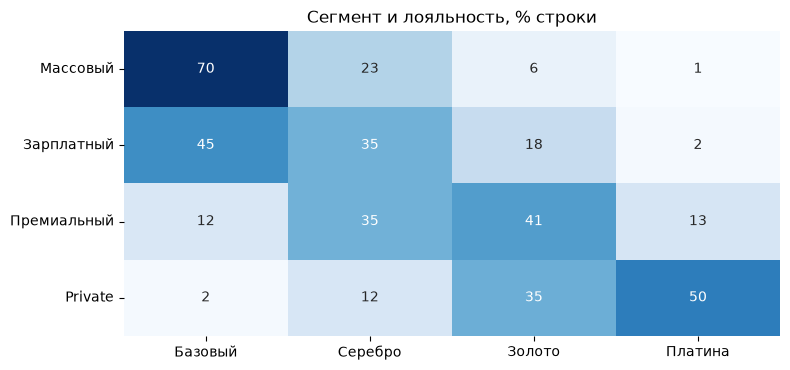

Доход и сегмент
segment           Массовый  Зарплатный  Премиальный  Private
income_group                                                
до 50 тыс.             781         194            4        0
50–100 тыс.           1392         857          111        0
100–200 тыс.           265         371          472       15
свыше 200 тыс.           4           7          188      193
доход подставлен       458         141          116       43


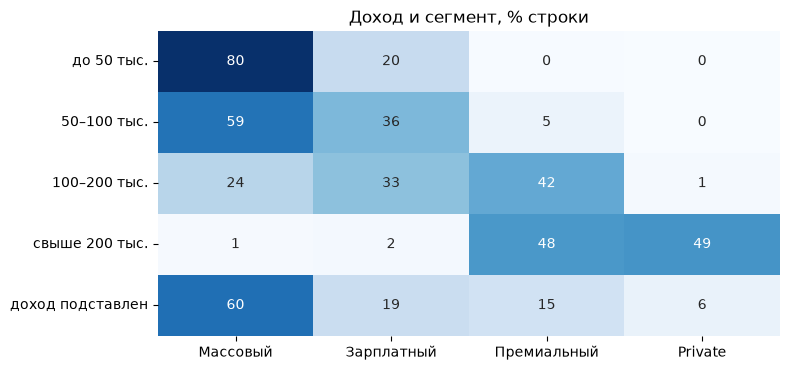

Доход и лояльность
loyalty_tier      Базовый  Серебро  Золото  Платина
income_group                                       
до 50 тыс.            659      223      87       10
50–100 тыс.          1354      674     287       45
100–200 тыс.          417      356     263       87
свыше 200 тыс.         27       93     158      114
доход подставлен      393      193     120       52


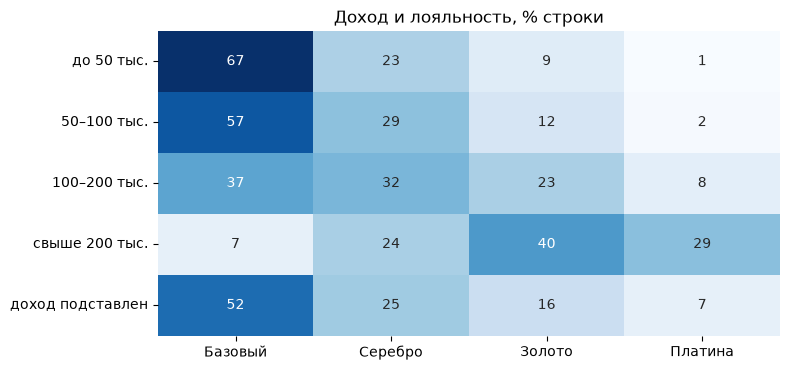

Тип карты и сегмент
segment      Массовый  Зарплатный  Премиальный  Private
card_type                                              
Дебетовая        2337        1139          399       47
Кредитная         535         398          208       47
Премиальная        28          33          284      157


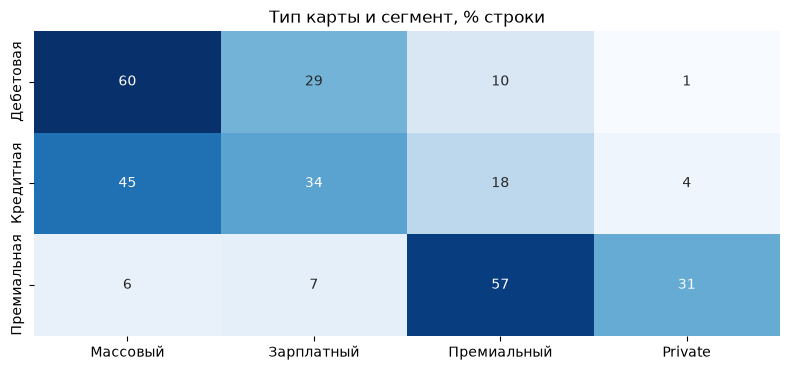

In [203]:
profile = clients[[
    "client_id", "segment", "loyalty_tier", "card_type", "has_mobile_app",
    "birth_date", "monthly_income", "income_imputed", "false_income",
]].copy()
observed = ~profile["income_imputed"] & ~profile["false_income"]
profile["income_group"] = "доход подставлен"
profile.loc[observed, "income_group"] = pd.cut(
    profile.loc[observed, "monthly_income"],
    [0, 50000, 100000, 200000, np.inf],
    labels=["до 50 тыс.", "50–100 тыс.", "100–200 тыс.", "свыше 200 тыс."],
    right=False,
).astype(str)
profile["age_group"] = pd.cut(
    (pd.Timestamp("2025-06-30") - profile["birth_date"]).dt.days / 365.25,
    [0, 35, 50, 65, 120],
    labels=["до 35", "35–50", "50–65", "65+"],
    right=False,
)
profile = profile.loc[profile["segment"] != "Неопределено"].copy()

rub_2024 = transactions.loc[
    (transactions["status"] == "успешно")
    & (transactions["amount"] > 0)
    & (transactions["currency"] == "RUB")
    & (transactions["txn_datetime"] >= "2024-01-01")
    & (transactions["txn_datetime"] < "2025-01-01")
    & (transactions["client_id"].isin(profile["client_id"]))
]
profile["spend"] = profile["client_id"].map(rub_2024.groupby("client_id")["amount"].sum() / 12).fillna(0)

segments = ["Массовый", "Зарплатный", "Премиальный", "Private"]
loyalty = ["Базовый", "Серебро", "Золото", "Платина"]
incomes = ["до 50 тыс.", "50–100 тыс.", "100–200 тыс.", "свыше 200 тыс.", "доход подставлен"]
order_cat = [
    "Одежда и обувь", "Развлечения и досуг", "Кафе и рестораны", "Продукты", "АЗС",
    "Аптеки", "Связь и интернет", "Онлайн-сервисы", "Транспорт",
]


def row_heatmap(row, col, row_order, col_order, title):
    table = pd.crosstab(profile[row], profile[col]).reindex(index=row_order, columns=col_order)
    share = table.div(table.sum(axis=1), axis=0) * 100
    print(title)
    print(table.astype(int).to_string())
    fig, ax = plt.subplots(figsize=(8, 3.8))
    sns.heatmap(share, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(title + ", % строки")
    ax.set_xlabel("")
    ax.set_ylabel("")
    fig.tight_layout()
    plt.show()


print("Клиентов в таблицах:", len(profile), "из", len(clients))
row_heatmap("segment", "loyalty_tier", segments, loyalty, "Сегмент и лояльность")
row_heatmap("income_group", "segment", incomes, segments, "Доход и сегмент")
row_heatmap("income_group", "loyalty_tier", incomes, loyalty, "Доход и лояльность")
row_heatmap(
    "card_type", "segment",
    ["Дебетовая", "Кредитная", "Премиальная"], segments,
    "Тип карты и сегмент",
)


Доля строки, все клиенты кроме 14 с сегментом «Неопределено».

Массовый: базовый 70%, платина 1%. Зарплатный: базовый 45%, золото 18%. Премиальный: золото 41%, платина 13%, базовый 12%. Private: платина 50%, золото 36%, базовый 2%.

Доход до 50 тыс.: массовый 80%, Private нет. 50–100 тыс.: массовый 59%, премиальный 5%. 100–200 тыс.: массовый 24%, премиальный 42%, Private 1%. Свыше 200 тыс.: массовый 1%, премиальный 48%, Private 49%.

Доход до 50 тыс.: базовый 67%, платина 1%. Свыше 200 тыс.: базовый 7%, золото 40%, платина 29%.

Дебетовая карта: массовый 60%. Премиальная: премиальный сегмент 57%, Private 31%, массовый 6%.


Доля суммы, %
category          Одежда и обувь  Развлечения и досуг  Кафе и рестораны  Продукты   АЗС  Аптеки  Связь и интернет  Онлайн-сервисы  Транспорт
income_group                                                                                                                                
до 50 тыс.                  27.8                 13.3              11.9      21.9  12.1     5.4               4.0             2.7        0.9
50–100 тыс.                 27.9                 14.8              12.8      20.5  12.0     4.8               3.8             2.6        0.8
100–200 тыс.                30.1                 17.5              14.8      15.9  12.4     3.5               2.9             2.3        0.6
свыше 200 тыс.              32.6                 21.5              16.7      11.4  11.0     2.1               2.0             2.3        0.4
доход подставлен            28.6                 16.9              14.3      17.9  11.7     4.2               3.3             2.4        0.7

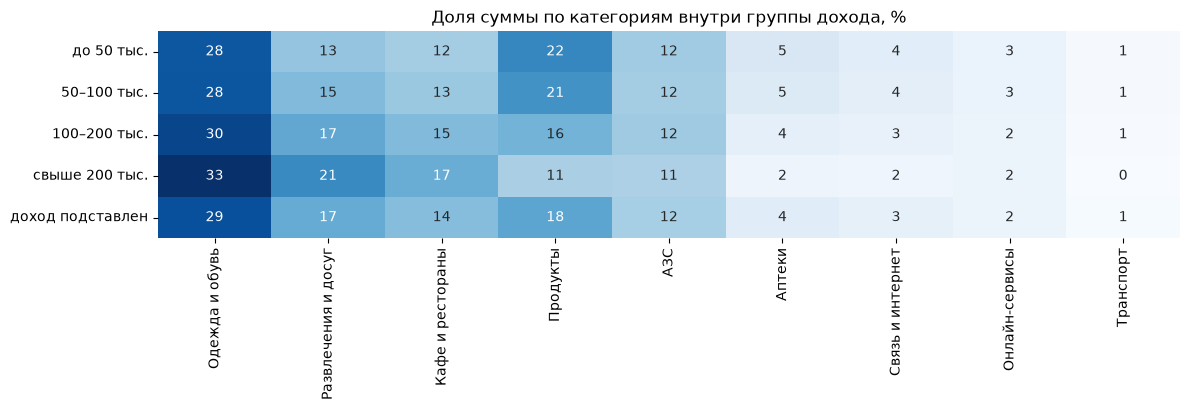

In [204]:
order_income = ["до 50 тыс.", "50–100 тыс.", "100–200 тыс.", "свыше 200 тыс.", "доход подставлен"]
order_cat = [
    "Одежда и обувь", "Развлечения и досуг", "Кафе и рестораны", "Продукты", "АЗС",
    "Аптеки", "Связь и интернет", "Онлайн-сервисы", "Транспорт",
]
linked = rub_2024.merge(profile[["client_id", "income_group"]], on="client_id")
sums = linked.groupby(["income_group", "category"])["amount"].sum().unstack().reindex(order_income).fillna(0)
share = sums.div(sums.sum(axis=1), axis=0) * 100
share = share[order_cat]
sizes = profile["income_group"].value_counts()
per_client = sums.div(sizes, axis=0) / 12
print("Доля суммы, %")
print(share.round(1).to_string())
print("Рублей на клиента в месяц")
print(per_client[order_cat].round(0).to_string())

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(share, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Доля суммы по категориям внутри группы дохода, %")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
plt.show()


Доля суммы успешных рублей за 2024. Доход до 50 тыс.: продукты 21,9%, одежда 27,8%, развлечения 13,3%, кафе 11,9%. Доход свыше 200 тыс.: продукты 11,4%, одежда 32,6%, развлечения 21,5%, кафе 16,7%. АЗС в обеих строках 12,1% и 11,0%.

Рублей на клиента в месяц, те же две группы: продукты 1707 и 2559, одежда 2170 и 7341, развлечения 1033 и 4831, кафе 928 и 3754.

Подставленный доход: продукты 17,9%, одежда 28,6%, развлечения 16,9%.


                  min       max  count
spend_group                           
1-я четверть      0.0    4943.0   1403
2-я четверть   4944.0    9009.0   1403
3-я четверть   9011.0   15080.0   1403
4-я четверть  15100.0  106247.0   1403
Доля суммы, %
category      Одежда и обувь  Развлечения и досуг  Кафе и рестораны  Продукты   АЗС  Аптеки  Связь и интернет  Онлайн-сервисы  Транспорт
spend_group                                                                                                                             
1-я четверть            24.3                 12.5              12.8      24.3  11.6     5.9               4.5             3.1        1.0
2-я четверть            26.6                 13.4              12.7      22.1  12.0     5.4               4.2             2.7        0.9
3-я четверть            28.6                 15.1              13.3      19.6  11.9     4.5               3.6             2.5        0.8
4-я четверть            30.5                 18.2              14.6

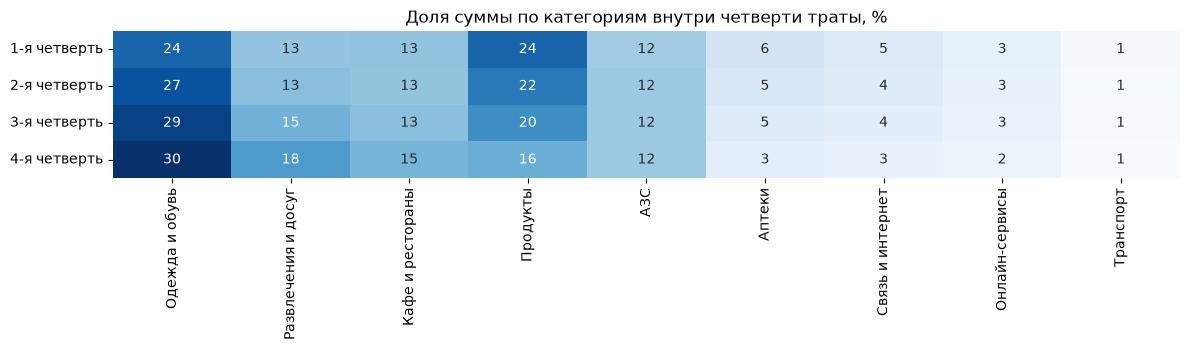

In [205]:
profile["spend_group"] = pd.qcut(
    profile["spend"], 4,
    labels=["1-я четверть", "2-я четверть", "3-я четверть", "4-я четверть"],
)
print(profile.groupby("spend_group", observed=True)["spend"].agg(["min", "max", "count"]).round(0))
linked = rub_2024.merge(profile[["client_id", "spend_group"]], on="client_id")
order = ["1-я четверть", "2-я четверть", "3-я четверть", "4-я четверть"]
sums = linked.groupby(["spend_group", "category"], observed=True)["amount"].sum().unstack().reindex(order).fillna(0)
share = sums.div(sums.sum(axis=1), axis=0) * 100
share = share[order_cat]
print("Доля суммы, %")
print(share.round(1).to_string())

fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(share, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Доля суммы по категориям внутри четверти траты, %")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
plt.show()


Нижняя четверть, до 4954 рублей в месяц: продукты 24,3%, одежда 24,3%, развлечения 12,5%, кафе 12,8%. Верхняя, от 15100: продукты 15,6%, одежда 30,5%, развлечения 18,2%, кафе 14,6%. АЗС 11,6% и 11,9%.


                  min       max  count
spend_group                           
1-я четверть      0.0    4943.0   1403
2-я четверть   4944.0    9009.0   1403
3-я четверть   9011.0   15080.0   1403
4-я четверть  15100.0  106247.0   1403
Четверть траты и сегмент
segment       Массовый  Зарплатный  Премиальный  Private
spend_group                                             
1-я четверть       834         373          155       41
2-я четверть       998         330           64       11
3-я четверть       732         437          205       29
4-я четверть       336         430          467      170


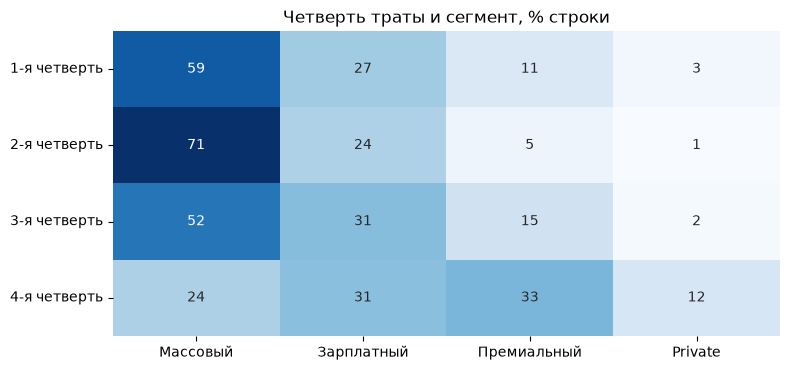

Четверть траты и лояльность
loyalty_tier  Базовый  Серебро  Золото  Платина
spend_group                                    
1-я четверть      762      387     195       59
2-я четверть      846      374     152       31
3-я четверть      755      387     200       61
4-я четверть      487      391     368      157


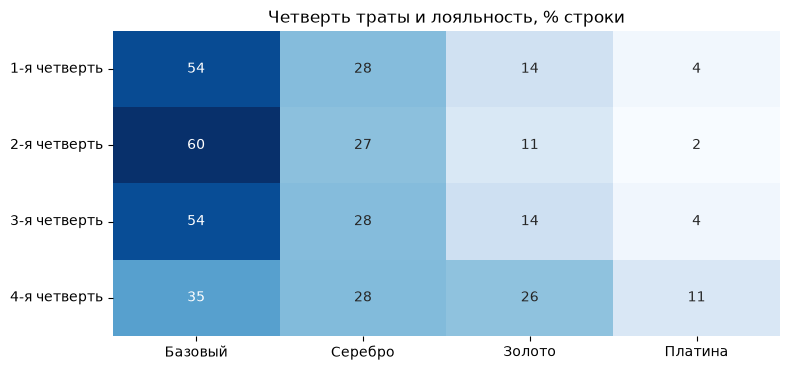

In [206]:
profile["spend_group"] = pd.qcut(
    profile["spend"], 4,
    labels=["1-я четверть", "2-я четверть", "3-я четверть", "4-я четверть"],
)
quarters = ["1-я четверть", "2-я четверть", "3-я четверть", "4-я четверть"]
print(profile.groupby("spend_group", observed=True)["spend"].agg(["min", "max", "count"]).round(0))
row_heatmap("spend_group", "segment", quarters, segments, "Четверть траты и сегмент")
row_heatmap("spend_group", "loyalty_tier", quarters, loyalty, "Четверть траты и лояльность")


Четверти — успешные рубли за 2024 на клиента, делённые на 12. Вторая четверть самая массовая: массовый сегмент 71%. Четвёртая: массовый 24%, зарплатный 31%, премиальный 33%, Private 12%.

Серебро во всех четвертях 27–28%. Базовый: 54% в первой и 35% в четвёртой. Золото 14% и 26%, платина 4% и 11%.


category     Одежда и обувь  Развлечения и досуг  Кафе и рестораны  Продукты   АЗС  Аптеки  Связь и интернет  Онлайн-сервисы  Транспорт
segment                                                                                                                                
Массовый               27.4                 13.5              11.5      22.8  11.2     5.7               4.2             2.7        0.9
Зарплатный             28.1                 14.7              13.8      19.2  13.2     4.2               3.5             2.5        0.8
Премиальный            30.7                 20.4              16.3      12.8  12.3     2.6               2.3             2.1        0.5
Private                34.8                 22.5              17.1       9.0  10.1     1.9               1.8             2.4        0.3


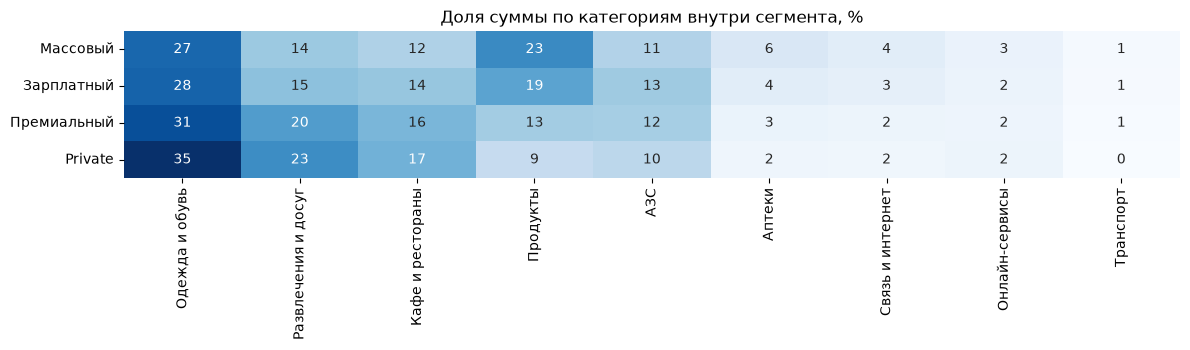

In [207]:
linked = rub_2024.merge(profile[["client_id", "segment"]], on="client_id")
sums = linked.groupby(["segment", "category"], observed=True)["amount"].sum().unstack()
sums = sums.reindex(index=segments).fillna(0)[order_cat]
share = sums.div(sums.sum(axis=1), axis=0) * 100
print(share.round(1).to_string())
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(share, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Доля суммы по категориям внутри сегмента, %")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
plt.show()


Массовый: продукты 23%, одежда 27%, развлечения 14%, кафе 12%. Private: продукты 9%, одежда 35%, развлечения 22%, кафе 17%. АЗС 11% и 10%.


category      Одежда и обувь  Развлечения и досуг  Кафе и рестораны  Продукты   АЗС  Аптеки  Связь и интернет  Онлайн-сервисы  Транспорт
loyalty_tier                                                                                                                            
Базовый                 28.0                 14.3              12.4      21.1  11.9     5.0               3.9             2.6        0.8
Серебро                 29.3                 16.4              14.1      17.8  12.0     4.0               3.2             2.4        0.7
Золото                  30.2                 19.0              15.4      14.4  12.1     3.2               2.7             2.3        0.6
Платина                 31.6                 20.7              16.8      12.1  11.3     2.4               2.2             2.4        0.5


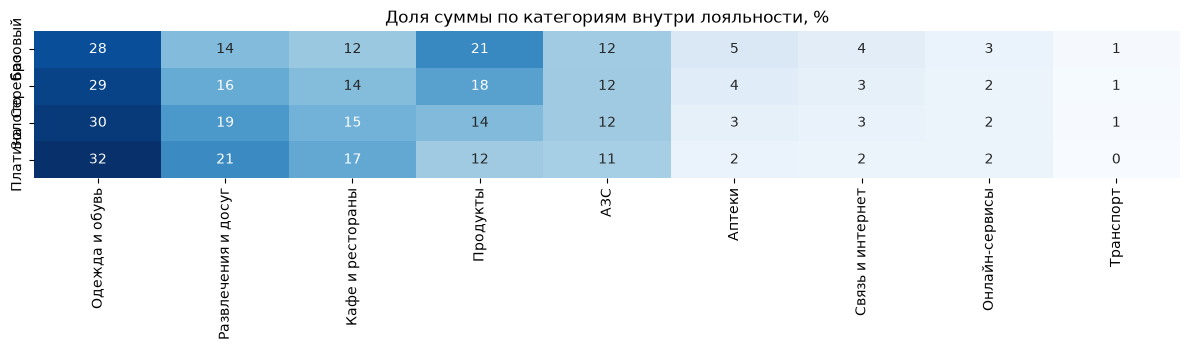

In [208]:
linked = rub_2024.merge(profile[["client_id", "loyalty_tier"]], on="client_id")
sums = linked.groupby(["loyalty_tier", "category"], observed=True)["amount"].sum().unstack()
sums = sums.reindex(index=loyalty).fillna(0)[order_cat]
share = sums.div(sums.sum(axis=1), axis=0) * 100
print(share.round(1).to_string())
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(share, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
ax.set_title("Доля суммы по категориям внутри лояльности, %")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
plt.show()


Базовый: продукты 21%, одежда 28%, развлечения 14%, кафе 12%. Платина: продукты 12%, одежда 32%, развлечения 21%, кафе 17%.


Доля суммы по каналам внутри возраста, %
channel    Карта  Онлайн-банк   СБП  Токен
age_group                                 
до 35       41.2         12.7  21.5   24.6
35–50       49.1         14.0  19.4   17.5
50–65       59.1         15.6  15.7    9.5
65+         56.9         17.1  17.0    9.0


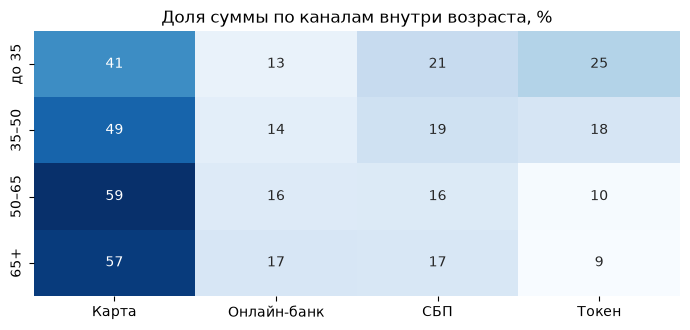

Доля суммы по каналам и приложение, %
channel         Карта  Онлайн-банк   СБП  Токен
has_mobile_app                                 
Нет              57.2         16.3  17.1    9.4
Да               50.9         14.2  18.4   16.6


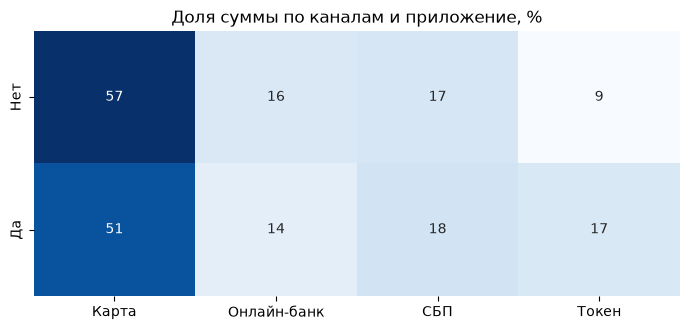

In [209]:
ages = ["до 35", "35–50", "50–65", "65+"]
linked = rub_2024.merge(profile[["client_id", "age_group", "has_mobile_app"]], on="client_id")


def channel_heatmap(column, order, title):
    sums = linked.groupby([column, "channel"], observed=True)["amount"].sum().unstack()
    sums = sums.reindex(order).fillna(0)
    share = sums.div(sums.sum(axis=1), axis=0) * 100
    print(title)
    print(share.round(1).to_string())
    fig, ax = plt.subplots(figsize=(7, 3.4))
    sns.heatmap(share, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    fig.tight_layout()
    plt.show()


channel_heatmap("age_group", ages, "Доля суммы по каналам внутри возраста, %")
channel_heatmap("has_mobile_app", ["Нет", "Да"], "Доля суммы по каналам и приложение, %")


До 35 лет: карта 41%, токен 25%, СБП 22%. 65+: карта 57%, токен 9%, СБП 17%.

Без приложения токен 9%, с приложением 17%. Карта 57% и 51%.


## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

Метрика — рубли в месяц. Сумма успешных операций с положительной суммой в рублях делится на число месяцев окна, в которых карта уже открыта. Месяц открытия входит. Базовое окно — 2024 год. Оцениваемое — январь–июнь 2025. Если карта открыта только в 2025, базового значения нет.


In [210]:
opened = clients["card_open_date"].dt.to_period("M").dt.to_timestamp()

def open_months(opened, start, end):
    left = opened.where(opened > start, start)
    months = (end.year - left.dt.year) * 12 + (end.month - left.dt.month) + 1
    return months.where(opened <= end, 0).astype(int)

rub = transactions.loc[
    (transactions["status"] == "успешно")
    & (transactions["amount"] > 0)
    & (transactions["currency"] == "RUB")
].copy()
rub["month"] = rub["txn_datetime"].dt.to_period("M").dt.to_timestamp()

def window_values(start, end, agg):
    part = rub.loc[(rub["month"] >= start) & (rub["month"] <= end)]
    if agg == "sum":
        return part.groupby("client_id")["amount"].sum()
    return part.groupby("client_id").size()

activity = clients[["client_id", "card_open_date"]].copy()
activity["base_months"] = open_months(opened, pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-01"))
activity["eval_months"] = open_months(opened, pd.Timestamp("2025-01-01"), pd.Timestamp("2025-06-01"))
activity["base_sum"] = activity["client_id"].map(window_values("2024-01-01", "2024-12-01", "sum")).fillna(0)
activity["eval_sum"] = activity["client_id"].map(window_values("2025-01-01", "2025-06-01", "sum")).fillna(0)
activity["base_n"] = activity["client_id"].map(window_values("2024-01-01", "2024-12-01", "count")).fillna(0)
activity["eval_n"] = activity["client_id"].map(window_values("2025-01-01", "2025-06-01", "count")).fillna(0)
activity["base_rate"] = activity["base_sum"] / activity["base_months"].replace(0, np.nan)
activity["eval_rate"] = activity["eval_sum"] / activity["eval_months"].replace(0, np.nan)
activity["base_n_rate"] = activity["base_n"] / activity["base_months"].replace(0, np.nan)
activity["eval_n_rate"] = activity["eval_n"] / activity["eval_months"].replace(0, np.nan)

full = activity["base_months"] == 12
part = (activity["base_months"] > 0) & (activity["base_months"] < 12)
none = activity["base_months"] == 0
print("Карта открыта до января 2024, клиентов:", int(full.sum()))
print("Карта открыта в течение 2024, клиентов:", int(part.sum()))
print("Карта открыта в 2025, за 2024 сравнивать не с чем:", int(none.sum()))
print(
    "Рублей в месяц, старая карта:",
    round(activity.loc[full, "base_rate"].mean()),
    "в 2024 и",
    round(activity.loc[full, "eval_rate"].mean()),
    "в 2025",
)
print(
    "Рублей в месяц, карта открыта в 2024:",
    round(activity.loc[part, "base_rate"].mean()),
    "в 2024 и",
    round(activity.loc[part, "eval_rate"].mean()),
    "в 2025",
)

comparable = activity.loc[full].copy()
comparable["sum_change"] = comparable["eval_rate"] / comparable["base_rate"] - 1
comparable["n_change"] = comparable["eval_n_rate"] / comparable["base_n_rate"] - 1
print("Типичный клиент со старой картой, рублей в месяц, :", round(comparable["sum_change"].median() * 100),'%')
print("Типичный клиент со старой картой, операций в месяц:", round(comparable["n_change"].median() * 100),'%')
sum_only = (comparable["sum_change"] < -0.2) & (comparable["n_change"] >= -0.2)
n_only = (comparable["n_change"] < -0.2) & (comparable["sum_change"] >= -0.2)
print("Рублей в месяц меньше на 20% или сильнее, операций нет:", int(sum_only.sum()))
print("Операций меньше на 20% или сильнее, рублей в месяц нет:", int(n_only.sum()))
part_change = activity.loc[part, "eval_rate"] / activity.loc[part, "base_rate"] - 1
print("Типичный клиент с картой 2024 года, рублей в месяц: +", round(part_change.median() * 100),'%')


Карта открыта до января 2024, клиентов: 4827
Карта открыта в течение 2024, клиентов: 425
Карта открыта в 2025, за 2024 сравнивать не с чем: 374
Рублей в месяц, старая карта: 13308 в 2024 и 10106 в 2025
Рублей в месяц, карта открыта в 2024: 3649 в 2024 и 3752 в 2025
Типичный клиент со старой картой, рублей в месяц, : -33 %
Типичный клиент со старой картой, операций в месяц: -19 %
Рублей в месяц меньше на 20% или сильнее, операций нет: 800
Операций меньше на 20% или сильнее, рублей в месяц нет: 252
Типичный клиент с картой 2024 года, рублей в месяц: + 11 %


Карта открыта до января 2024: 4827 клиентов, 13308 рублей в месяц в 2024 и 10106 в 2025. Типичный такой клиент: рубли в месяц −33%, операции в месяц −19%.

Рублей в месяц меньше на 20% или сильнее, а число операций нет: 800. Операций меньше на 20% или сильнее, а рублей в месяц нет: 252.

Карта открыта в течение 2024: 425 клиентов, 3649 рублей в месяц в 2024 и 3752 в 2025. Типичный такой клиент: +11%.

Карта открыта в 2025: 374 клиента, за 2024 сравнивать не с чем.


## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

In [211]:
work = clients.merge(
    activity[["client_id", "base_months", "eval_months", "base_rate", "eval_rate", "base_sum"]],
    on="client_id",
)
observed = ~work["income_imputed"] & ~work["false_income"]
work["income_group"] = "доход подставлен"
work.loc[observed, "income_group"] = pd.cut(
    work.loc[observed, "monthly_income"],
    [0, 50000, 100000, 200000, np.inf],
    labels=["до 50 тыс.", "50–100 тыс.", "100–200 тыс.", "свыше 200 тыс."],
    right=False,
).astype(str)
work["change"] = work["eval_rate"] / work["base_rate"] - 1
work["lost"] = (work["base_rate"] - work["eval_rate"]) * work["eval_months"]

ready = work["marketing_opt_in"].eq("Да") & work["base_months"].eq(12) & work["base_rate"].gt(0)
fell = ready & work["change"].le(-0.2)
rich = work["income_group"].isin(["100–200 тыс.", "свыше 200 тыс."]) | work["segment"].isin(["Премиальный", "Private"])
loyal = work["loyalty_tier"].isin(["Золото", "Платина"])
high_spend = work["base_rate"].ge(15000)
mass_no_app = work["segment"].eq("Массовый") & work["has_mobile_app"].eq("Нет")

work["group"] = pd.NA
work.loc[fell & mass_no_app, "group"] = "массовый без приложения"
work.loc[fell & high_spend, "group"] = "трата от 15 тыс. в месяц"
work.loc[fell & loyal, "group"] = "золото или платина"
work.loc[fell & rich, "group"] = "доход от 100 тыс. или верхний сегмент"

campaign = work.loc[work["group"].notna(), ["client_id", "group"]].copy()
print("В списке:", len(campaign))
print(campaign["group"].value_counts().to_string())
for name, part in work.dropna(subset=["group"]).groupby("group"):
    print(
        name,
        "типичное изменение, %:",
        round(part["change"].median() * 100),
        "недобор, руб.:",
        round(part["lost"].sum()),
    )
campaign.to_csv("campaign_list.csv", index=False, encoding="utf-8")

print("Разных людей:", campaign["client_id"].nunique())
raw = pd.DataFrame({
    "доход или сегмент": fell & rich,
    "лояльность": fell & loyal,
    "трата": fell & high_spend,
    "массовый без приложения": fell & mass_no_app,
})
print("Подходят под два правила и больше:", int(raw.sum(axis=1).ge(2).sum()))

early = transactions.loc[
    (transactions["status"] == "успешно")
    & (transactions["amount"] > 0)
    & (transactions["currency"] == "RUB")
    & (transactions["txn_datetime"] >= "2024-01-01")
    & (transactions["txn_datetime"] < "2024-07-01"),
    ["client_id", "amount"],
]
work["h1_rate"] = work["client_id"].map(early.groupby("client_id")["amount"].sum()).fillna(0) / 6
work["change_h1"] = work["eval_rate"] / work["h1_rate"].replace(0, np.nan) - 1

who = pd.Series(pd.NA, index=work.index, dtype="object")
who.loc[ready & mass_no_app] = "массовый без приложения"
who.loc[ready & high_spend] = "трата от 15 тыс. в месяц"
who.loc[ready & loyal] = "золото или платина"
who.loc[ready & rich] = "доход от 100 тыс. или верхний сегмент"
print("Все с этим признаком, до отбора по 20%")
for name, part in work.loc[who.notna()].groupby(who.loc[who.notna()]):
    print(
        name,
        "человек:",
        len(part),
        "к всему 2024, %:",
        round(part["change"].median() * 100),
        "к январю–июню 2024, %:",
        round(part["change_h1"].median() * 100),
    )


В списке: 1717
group
доход от 100 тыс. или верхний сегмент    708
массовый без приложения                  528
трата от 15 тыс. в месяц                 309
золото или платина                       172
доход от 100 тыс. или верхний сегмент типичное изменение, %: -48 недобор, руб.: 39726707
золото или платина типичное изменение, %: -55 недобор, руб.: 6435672
массовый без приложения типичное изменение, %: -67 недобор, руб.: 15329248
трата от 15 тыс. в месяц типичное изменение, %: -56 недобор, руб.: 21363398
Разных людей: 1717
Подходят под два правила и больше: 661
Все с этим признаком, до отбора по 20%
доход от 100 тыс. или верхний сегмент человек: 1319 к всему 2024, %: -25 к январю–июню 2024, %: -17
золото или платина человек: 331 к всему 2024, %: -23 к январю–июню 2024, %: -16
массовый без приложения человек: 666 к всему 2024, %: -60 к январю–июню 2024, %: -57
трата от 15 тыс. в месяц человек: 479 к всему 2024, %: -38 к январю–июню 2024, %: -33


В список входят клиенты с согласием на связь, карта открыта до 2024, рубли в месяц ниже на 20% или больше. Если клиент подходит под несколько правил, остаётся первое.

Доход от 100 тыс. или сегмент Премиальный / Private: 708 человек, типичное изменение −48%, недобор 39,7 млн рублей.

Золото или платина: 172 человека, −55%, недобор 6,4 млн.

В 2024 от 15 000 рублей в месяц: 309 человек, −56%, недобор 21,4 млн.

Массовый сегмент без приложения: 528 человек, −67%, недобор 15,3 млн.

Вместе 1717. Под два правила и больше до приоритета подходят 661 человек, в списке каждый client_id один раз. Отдельное правило только для премиального сегмента после дохода даёт меньше 150 человек, поэтому этот сегмент стоит в первом правиле.


### 7.1. Кого в кампанию не берём и почему

In [212]:
print("Нет согласия:", int(work["marketing_opt_in"].eq("Нет").sum()))
print("Карта открыта в 2025:", int(work["base_months"].eq(0).sum()))
print("Карта открыта в течение 2024:", int(work["base_months"].between(1, 11).sum()))
print("Согласие есть, карта весь 2024, падение меньше 20%:", int((ready & ~fell).sum()))
print("Падение от 20%, в группы не вошли:", int((fell & work["group"].isna()).sum()))


Нет согласия: 636
Карта открыта в 2025: 374
Карта открыта в течение 2024: 425
Согласие есть, карта весь 2024, падение меньше 20%: 1690
Падение от 20%, в группы не вошли: 880


Нет согласия: 636. Карта открыта в 2025: 374, сравнивать не с чем. Карта открыта в течение 2024: 425. Согласие есть и карта весь 2024, но падение меньше 20%: 1690. Падение от 20%, но под четыре правила не попали: 880.


## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [213]:
sizes = clients["branch_code"].value_counts()
print("Отделений:", int(sizes.size), "самое большое:", int(sizes.max()))

age = (pd.Timestamp("2025-06-30") - clients["birth_date"]).dt.days / 365.25
print("Максимальный возраст на 30.06.2025:", round(age.max(), 1))

neg = transactions.loc[transactions["amount"] < 0]
print("Отрицательных сумм:", len(neg), "из них возврат:", int((neg["status"] == "возврат").sum()))

flow = transactions.copy()
flow["period"] = np.where(flow["txn_datetime"] < "2025-01-01", "2024", "2025")
share = flow.groupby("period")["status"].value_counts(normalize=True).unstack().fillna(0)
print("Доля отказов, 2024 и 2025:", round(share.loc["2024", "отклонено"], 3), round(share.loc["2025", "отклонено"], 3))

login = clients.loc[clients["app_last_login"].notna(), "app_last_login"].dt.to_period("M").value_counts()
print("Клиентов с последним входом в один месяц, от и до:", int(login.min()), int(login.max()))

rub = transactions.loc[
    (transactions["status"] == "успешно")
    & (transactions["amount"] > 0)
    & (transactions["currency"] == "RUB")
].copy()
rub["month"] = rub["txn_datetime"].dt.to_period("M").dt.to_timestamp()
by_month = rub.groupby("month")["amount"].sum()
print("Рубли января 2025 к январю 2024:", round(by_month.loc["2025-01-01"] / by_month.loc["2024-01-01"], 2))

succ = transactions.loc[transactions["status"] == "успешно"]
other = succ.loc[(succ["currency"] != "RUB") & (succ["amount"] > 0), "amount"].sum()
rub_sum = succ.loc[(succ["currency"] == "RUB") & (succ["amount"] > 0), "amount"].sum()
print("Успешных не в рублях:", int((succ["currency"] != "RUB").sum()), "из", len(succ))
print("Их сумма к сумме рублей:", round(other / rub_sum, 5))

mcc = rub.groupby(["month", "mcc_code"])["amount"].sum().unstack().fillna(0)
base = mcc.loc[mcc.index < "2025-01-01"].mean()
later = mcc.loc[mcc.index >= "2025-01-01"].mean()
chg = ((later - base) / base).sort_values()
print("Кодов MCC:", mcc.shape[1], "худшее изменение рублей:", round(chg.iloc[0], 2))

months = pd.date_range("2024-01-01", "2025-06-01", freq="MS")
grid = clients[["client_id", "card_open_date"]].copy()
grid["open_m"] = grid["card_open_date"].dt.to_period("M").dt.to_timestamp()
grid = grid.assign(key=1).merge(pd.DataFrame({"month": months, "key": 1}), on="key")
grid["tenure"] = (
    (grid["month"].dt.year - grid["open_m"].dt.year) * 12
    + (grid["month"].dt.month - grid["open_m"].dt.month)
)
grid = grid.loc[grid["tenure"] >= 0]
exposed = grid.groupby("tenure")["client_id"].nunique()
ops = life.groupby("tenure").size()
money = life.groupby("tenure")["amount"].sum()
for point in (12, 60):
    print(
        point, "месяц с получения карты",
        "операций на клиента:", round(ops.loc[point] / exposed.loc[point], 1),
        "рублей на клиента:", round(money.loc[point] / exposed.loc[point]),
    )

scored = work.loc[ready].copy()
scored["sat"] = scored["satisfaction_score"].map(lambda x: str(int(x)) if pd.notna(x) else "нет оценки")
print("Типичное изменение рублей в месяц, %, по оценке:")
print((scored.groupby("sat")["change"].median() * 100).round(0).to_string())


Отделений: 840 самое большое: 17
Максимальный возраст на 30.06.2025: 88.9
Отрицательных сумм: 7067 из них возврат: 7067
Доля отказов, 2024 и 2025: 0.02 0.019
Клиентов с последним входом в один месяц, от и до: 155 223
Рубли января 2025 к январю 2024: 0.88
Успешных не в рублях: 2280 из 574614
Их сумма к сумме рублей: 4e-05
Кодов MCC: 9 худшее изменение рублей: -0.36
12 месяц с получения карты операций на клиента: 6.7 рублей на клиента: 12748
60 месяц с получения карты операций на клиента: 6.3 рублей на клиента: 11942
Типичное изменение рублей в месяц, %, по оценке:
sat
1            -35.0
2            -31.0
3            -26.0
4            -33.0
5            -23.0
нет оценки   -36.0


Карту не перестают использовать со временем: на 12-м месяце после открытия 6,8 операции и около 13 тыс. рублей на клиента, на 60-м — 6,3 операции и около 12 тыс.

Отказы не выросли: доля 0,020 в 2024 и 0,019 в 2025.

Приложение не отключилось. Месяц последнего входа: от 155 до 223 клиентов в месяц, включая 2025.

Один MCC не обнулился. Кодов 9, худшее изменение суммы −36%.

Осталные валюты мало влияют: 2280 успешных операций из 574614, их сумма к рублям 0,00004.

Отрицательные суммы — возвраты: 7067 строк, все со статусом «возврат».

Январь 2025 — не только конец декабря: рублей 88% от января 2024.

Отделения: 840 кодов, в самом большом 17 клиентов.

Оценка не отделяет группу: оценка 1 и «нет оценки» около −35%, оценка 5 около −23%.


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [214]:
# clean.to_parquet("clean_data.parquet", index=False)
# cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")

In [215]:
clients.to_parquet("clients_clean.parquet", index=False)
transactions.to_parquet("transactions_clean.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")
print("клиенты", len(clients))
print("операции", len(transactions))
print("журнал", len(cleaning_log))
print("список", len(campaign), "уникальных", campaign["client_id"].nunique())


клиенты 5626
операции 593270
журнал 15
список 1717 уникальных 1717


Очищенные таблицы две, исходных файла тоже два: clients_clean.parquet — 5626 клиентов, transactions_clean.parquet — 593270 операций. Журнал cleaning_log.csv — 15 строк, список campaign_list.csv — 1717 человек, каждый client_id один раз.
